In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

In [71]:
df = pd.read_csv('../data/openpowerlifting.csv')

# selecting only SBD competitions
df = df[df['Event'] == 'SBD']

# removing incomplete rows
df_clean = df.dropna(subset=['TotalKg','BodyweightKg'])

# converting dates 
df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce')
df_clean['Year'] = df_clean['Date'].dt.year


In [18]:
# Info sul dataset
print("\n" + "=" * 80)
print("TIPI DI DATI E VALORI MANCANTI")
print("=" * 80)
print(df.info())

# Valori mancanti per colonna
print("\n" + "=" * 80)
print("VALORI MANCANTI PER COLONNA")
print("=" * 80)
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': missing_pct
}).sort_values('Percentage', ascending=False)
print(missing_df[missing_df['Missing Values'] > 0])

# Statistiche descrittive
print("\n" + "=" * 80)
print("STATISTICHE DESCRITTIVE")
print("=" * 80)
print(df.describe())

# Duplicati
print("\n" + "=" * 80)
print("DUPLICATI")
print("=" * 80)
duplicates = df.duplicated().sum()
print(f"Numero di righe duplicate: {duplicates}")


TIPI DI DATI E VALORI MANCANTI
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1423354 entries, 0 to 1423353
Data columns (total 37 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Name             1423354 non-null  object 
 1   Sex              1423354 non-null  object 
 2   Event            1423354 non-null  object 
 3   Equipment        1423354 non-null  object 
 4   Age              757527 non-null   float64
 5   AgeClass         786800 non-null   object 
 6   Division         1415176 non-null  object 
 7   BodyweightKg     1406622 non-null  float64
 8   WeightClassKg    1410042 non-null  object 
 9   Squat1Kg         337580 non-null   float64
 10  Squat2Kg         333349 non-null   float64
 11  Squat3Kg         323842 non-null   float64
 12  Squat4Kg         3696 non-null     float64
 13  Best3SquatKg     1031450 non-null  float64
 14  Bench1Kg         499779 non-null   float64
 15  Bench2Kg         493486 non-null  

VISUALIZATION 1: Weight Class Distribution by Sex (Separate Classes)


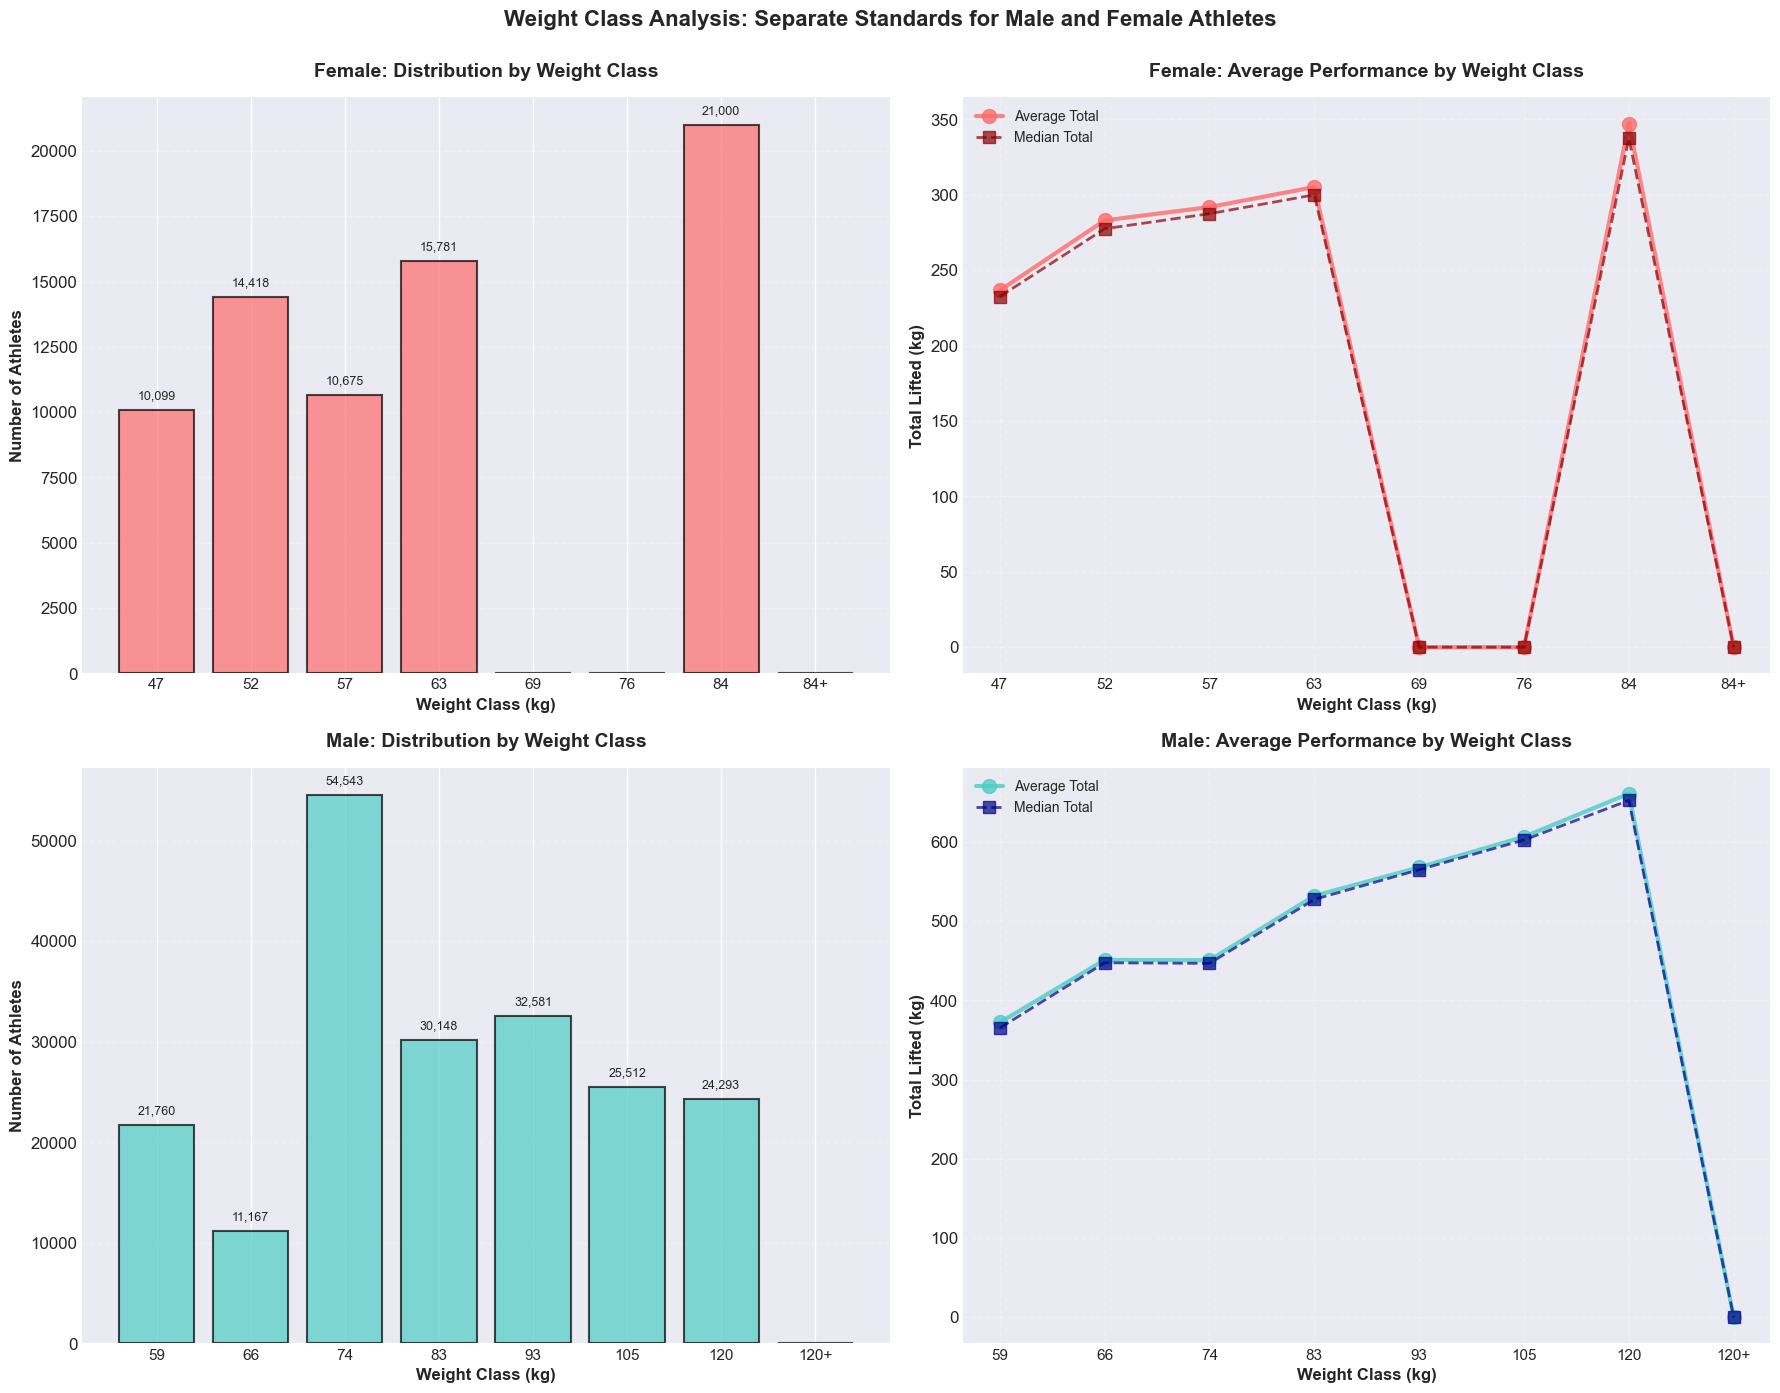


✓ Weight class visualization created with separate classes for each sex!

Female - Top 3 classes by participation:
  1. 84kg: 21,000 athletes
  2. 63kg: 15,781 athletes
  3. 52kg: 14,418 athletes

Male - Top 3 classes by participation:
  1. 74kg: 54,543 athletes
  2. 93kg: 32,581 athletes
  3. 83kg: 30,148 athletes


In [72]:
# ============================================================================
# VISUALIZATION 1: Weight Class Distribution - SEPARATE BY SEX
# Uomini e donne hanno classi di peso diverse
# ============================================================================

print("=" * 80)
print("VISUALIZATION 1: Weight Class Distribution by Sex (Separate Classes)")
print("=" * 80)

# Prepare data
df_viz1 = df_clean[df_clean['WeightClassKg'].notna()].copy()

# Define standard weight classes for each sex
MALE_CLASSES = ['59', '66', '74', '83', '93', '105', '120', '120+']
FEMALE_CLASSES = ['47', '52', '57', '63', '69', '76', '84', '84+']

# Function to standardize weight class labels
def standardize_weight_class(wc_str, sex):
    """Standardize weight class format"""
    if pd.isna(wc_str):
        return None
    wc_str = str(wc_str).strip()
    
    # Define target classes based on sex
    target_classes = MALE_CLASSES if sex == 'M' else FEMALE_CLASSES
    
    # Try to match to standard classes
    for std_class in target_classes:
        if std_class.replace('+', '') in wc_str.replace('+', ''):
            return std_class
    
    return None

# Apply standardization
df_viz1['WeightClassStd'] = df_viz1.apply(
    lambda row: standardize_weight_class(row['WeightClassKg'], row['Sex']), axis=1
)

df_viz1 = df_viz1[df_viz1['WeightClassStd'].notna()]

# Calculate statistics
stats_by_sex = {}
for sex, classes in [('M', MALE_CLASSES), ('F', FEMALE_CLASSES)]:
    df_sex = df_viz1[df_viz1['Sex'] == sex]
    stats = df_sex.groupby('WeightClassStd').agg({
        'TotalKg': ['count', 'mean', 'median'],
        'Wilks': 'mean'
    }).reindex(classes)
    stats.columns = ['Count', 'AvgTotal', 'MedianTotal', 'AvgWilks']
    stats_by_sex[sex] = stats

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
colors = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== ROW 1: FEMALE =====
# Left: Distribution
ax_f_dist = axes[0, 0]
female_stats = stats_by_sex['F']
x_f = np.arange(len(FEMALE_CLASSES))

bars_f = ax_f_dist.bar(x_f, female_stats['Count'].fillna(0), 
                       color=colors['F'], edgecolor='black', linewidth=1.5, alpha=0.7)

ax_f_dist.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_f_dist.set_ylabel('Number of Athletes', fontsize=12, fontweight='bold')
ax_f_dist.set_title('Female: Distribution by Weight Class', fontsize=14, fontweight='bold', pad=15)
ax_f_dist.set_xticks(x_f)
ax_f_dist.set_xticklabels(FEMALE_CLASSES, fontsize=11)
ax_f_dist.grid(axis='y', alpha=0.3, linestyle='--')

# Add count labels on bars
for i, (bar, count) in enumerate(zip(bars_f, female_stats['Count'].fillna(0))):
    if count > 0:
        ax_f_dist.text(i, count + max(female_stats['Count'].fillna(0))*0.02, 
                      f'{int(count):,}', ha='center', fontsize=9)

# Right: Performance
ax_f_perf = axes[0, 1]

ax_f_perf.plot(x_f, female_stats['AvgTotal'].fillna(0), marker='o', linewidth=3, 
              markersize=10, color=colors['F'], label='Average Total', alpha=0.8)
ax_f_perf.plot(x_f, female_stats['MedianTotal'].fillna(0), marker='s', linewidth=2, 
              markersize=8, color='darkred', linestyle='--', label='Median Total', alpha=0.7)

ax_f_perf.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_f_perf.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax_f_perf.set_title('Female: Average Performance by Weight Class', fontsize=14, fontweight='bold', pad=15)
ax_f_perf.set_xticks(x_f)
ax_f_perf.set_xticklabels(FEMALE_CLASSES, fontsize=11)
ax_f_perf.legend(fontsize=10, loc='upper left')
ax_f_perf.grid(alpha=0.3, linestyle='--')

# ===== ROW 2: MALE =====
# Left: Distribution
ax_m_dist = axes[1, 0]
male_stats = stats_by_sex['M']
x_m = np.arange(len(MALE_CLASSES))

bars_m = ax_m_dist.bar(x_m, male_stats['Count'].fillna(0), 
                       color=colors['M'], edgecolor='black', linewidth=1.5, alpha=0.7)

ax_m_dist.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_m_dist.set_ylabel('Number of Athletes', fontsize=12, fontweight='bold')
ax_m_dist.set_title('Male: Distribution by Weight Class', fontsize=14, fontweight='bold', pad=15)
ax_m_dist.set_xticks(x_m)
ax_m_dist.set_xticklabels(MALE_CLASSES, fontsize=11)
ax_m_dist.grid(axis='y', alpha=0.3, linestyle='--')

# Add count labels on bars
for i, (bar, count) in enumerate(zip(bars_m, male_stats['Count'].fillna(0))):
    if count > 0:
        ax_m_dist.text(i, count + max(male_stats['Count'].fillna(0))*0.02, 
                      f'{int(count):,}', ha='center', fontsize=9)

# Right: Performance
ax_m_perf = axes[1, 1]

ax_m_perf.plot(x_m, male_stats['AvgTotal'].fillna(0), marker='o', linewidth=3, 
              markersize=10, color=colors['M'], label='Average Total', alpha=0.8)
ax_m_perf.plot(x_m, male_stats['MedianTotal'].fillna(0), marker='s', linewidth=2, 
              markersize=8, color='darkblue', linestyle='--', label='Median Total', alpha=0.7)

ax_m_perf.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_m_perf.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax_m_perf.set_title('Male: Average Performance by Weight Class', fontsize=14, fontweight='bold', pad=15)
ax_m_perf.set_xticks(x_m)
ax_m_perf.set_xticklabels(MALE_CLASSES, fontsize=11)
ax_m_perf.legend(fontsize=10, loc='upper left')
ax_m_perf.grid(alpha=0.3, linestyle='--')

plt.suptitle('Weight Class Analysis: Separate Standards for Male and Female Athletes', 
            fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("\n✓ Weight class visualization created with separate classes for each sex!")
print(f"\nFemale - Top 3 classes by participation:")
for i, (wc, count) in enumerate(female_stats['Count'].fillna(0).nlargest(3).items(), 1):
    if count > 0:
        print(f"  {i}. {wc}kg: {int(count):,} athletes")

print(f"\nMale - Top 3 classes by participation:")
for i, (wc, count) in enumerate(male_stats['Count'].fillna(0).nlargest(3).items(), 1):
    if count > 0:
        print(f"  {i}. {wc}kg: {int(count):,} athletes")

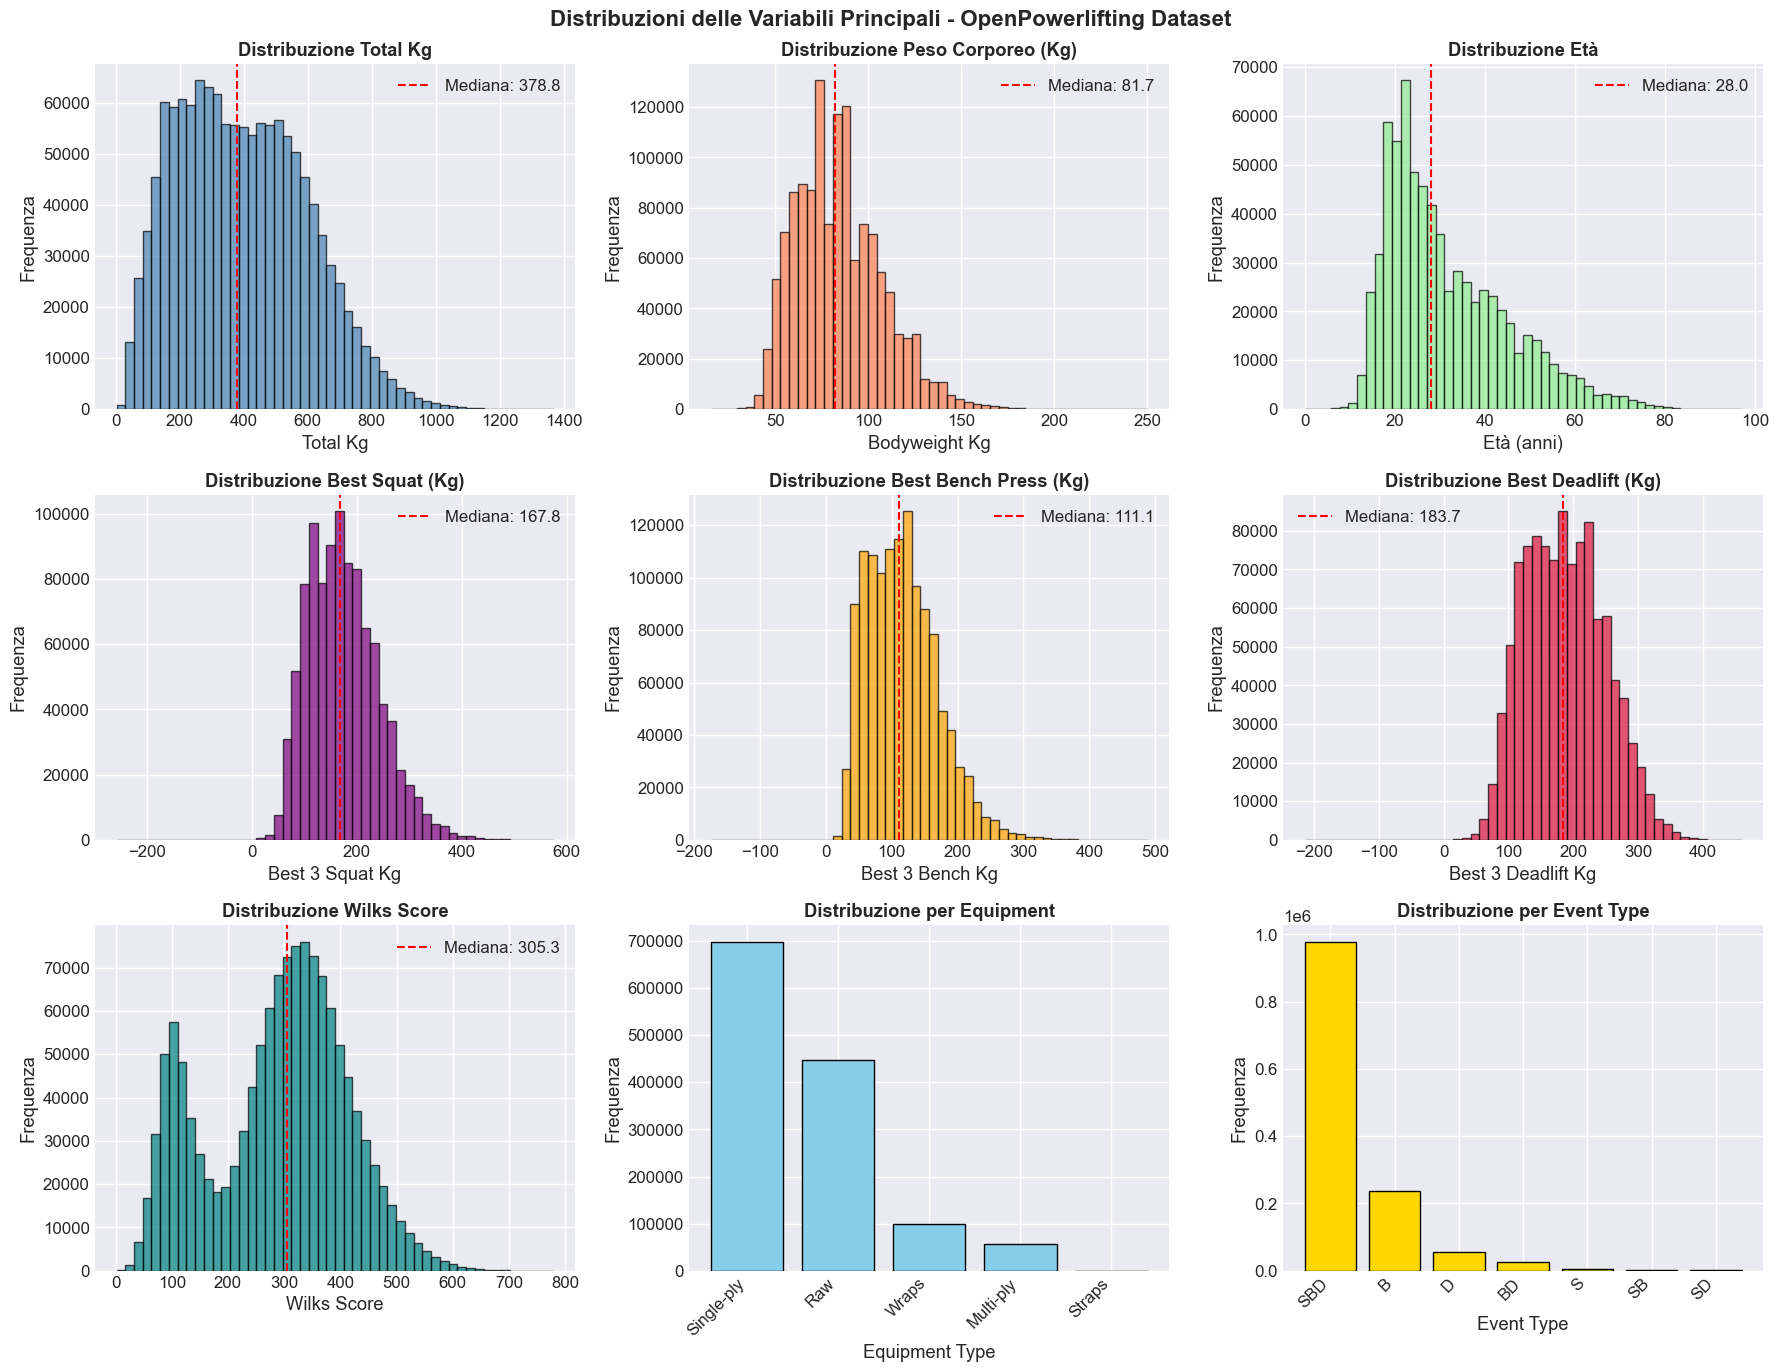


✓ Visualizzazioni create con successo!


In [25]:
# VISUALIZZAZIONI DELLE DISTRIBUZIONI
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle('Distribuzioni delle Variabili Principali - OpenPowerlifting Dataset', fontsize=16, fontweight='bold')

# 1. Distribuzione TotalKg
axes[0, 0].hist(df_clean['TotalKg'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribuzione Total Kg', fontweight='bold')
axes[0, 0].set_xlabel('Total Kg')
axes[0, 0].set_ylabel('Frequenza')
axes[0, 0].axvline(df_clean['TotalKg'].median(), color='red', linestyle='--', label=f'Mediana: {df_clean["TotalKg"].median():.1f}')
axes[0, 0].legend()

# 2. Distribuzione BodyweightKg
axes[0, 1].hist(df_clean['BodyweightKg'], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribuzione Peso Corporeo (Kg)', fontweight='bold')
axes[0, 1].set_xlabel('Bodyweight Kg')
axes[0, 1].set_ylabel('Frequenza')
axes[0, 1].axvline(df_clean['BodyweightKg'].median(), color='red', linestyle='--', label=f'Mediana: {df_clean["BodyweightKg"].median():.1f}')
axes[0, 1].legend()

# 3. Distribuzione Age
age_data = df_clean[df_clean['Age'].notna()]['Age']
axes[0, 2].hist(age_data, bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[0, 2].set_title('Distribuzione Età', fontweight='bold')
axes[0, 2].set_xlabel('Età (anni)')
axes[0, 2].set_ylabel('Frequenza')
axes[0, 2].axvline(age_data.median(), color='red', linestyle='--', label=f'Mediana: {age_data.median():.1f}')
axes[0, 2].legend()

# 4. Distribuzione Best3SquatKg
squat_data = df_clean[df_clean['Best3SquatKg'].notna()]['Best3SquatKg']
axes[1, 0].hist(squat_data, bins=50, color='purple', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Distribuzione Best Squat (Kg)', fontweight='bold')
axes[1, 0].set_xlabel('Best 3 Squat Kg')
axes[1, 0].set_ylabel('Frequenza')
axes[1, 0].axvline(squat_data.median(), color='red', linestyle='--', label=f'Mediana: {squat_data.median():.1f}')
axes[1, 0].legend()

# 5. Distribuzione Best3BenchKg
bench_data = df_clean[df_clean['Best3BenchKg'].notna()]['Best3BenchKg']
axes[1, 1].hist(bench_data, bins=50, color='orange', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Distribuzione Best Bench Press (Kg)', fontweight='bold')
axes[1, 1].set_xlabel('Best 3 Bench Kg')
axes[1, 1].set_ylabel('Frequenza')
axes[1, 1].axvline(bench_data.median(), color='red', linestyle='--', label=f'Mediana: {bench_data.median():.1f}')
axes[1, 1].legend()

# 6. Distribuzione Best3DeadliftKg
deadlift_data = df_clean[df_clean['Best3DeadliftKg'].notna()]['Best3DeadliftKg']
axes[1, 2].hist(deadlift_data, bins=50, color='crimson', edgecolor='black', alpha=0.7)
axes[1, 2].set_title('Distribuzione Best Deadlift (Kg)', fontweight='bold')
axes[1, 2].set_xlabel('Best 3 Deadlift Kg')
axes[1, 2].set_ylabel('Frequenza')
axes[1, 2].axvline(deadlift_data.median(), color='red', linestyle='--', label=f'Mediana: {deadlift_data.median():.1f}')
axes[1, 2].legend()

# 7. Distribuzione Wilks Score
wilks_data = df_clean[df_clean['Wilks'].notna()]['Wilks']
axes[2, 0].hist(wilks_data, bins=50, color='teal', edgecolor='black', alpha=0.7)
axes[2, 0].set_title('Distribuzione Wilks Score', fontweight='bold')
axes[2, 0].set_xlabel('Wilks Score')
axes[2, 0].set_ylabel('Frequenza')
axes[2, 0].axvline(wilks_data.median(), color='red', linestyle='--', label=f'Mediana: {wilks_data.median():.1f}')
axes[2, 0].legend()

# 8. Distribuzione per Equipment
equipment_counts = df_clean['Equipment'].value_counts()
axes[2, 1].bar(range(len(equipment_counts)), equipment_counts.values, color='skyblue', edgecolor='black')
axes[2, 1].set_title('Distribuzione per Equipment', fontweight='bold')
axes[2, 1].set_xlabel('Equipment Type')
axes[2, 1].set_ylabel('Frequenza')
axes[2, 1].set_xticks(range(len(equipment_counts)))
axes[2, 1].set_xticklabels(equipment_counts.index, rotation=45, ha='right')

# 9. Distribuzione per Event
event_counts = df_clean['Event'].value_counts()
axes[2, 2].bar(range(len(event_counts)), event_counts.values, color='gold', edgecolor='black')
axes[2, 2].set_title('Distribuzione per Event Type', fontweight='bold')
axes[2, 2].set_xlabel('Event Type')
axes[2, 2].set_ylabel('Frequenza')
axes[2, 2].set_xticks(range(len(event_counts)))
axes[2, 2].set_xticklabels(event_counts.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()



TOTAL KG DISTRIBUTION BY SEX - GENERAL ANALYSIS


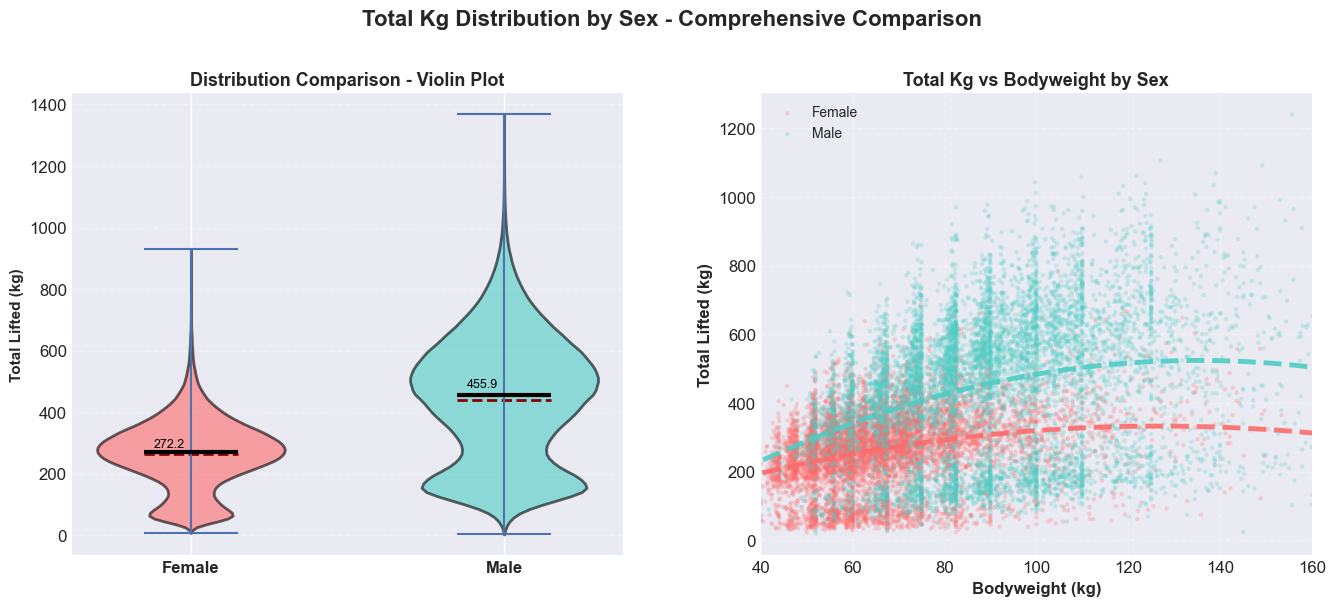

In [47]:
print("=" * 80)
print("TOTAL KG DISTRIBUTION BY SEX - GENERAL ANALYSIS")
print("=" * 80)

# Prepare data
df_general = df_clean.copy()

# Create visualization with only violin and scatter
fig = plt.figure(figsize=(16, 6))
gs = fig.add_gridspec(1, 2, hspace=0.3, wspace=0.25)

colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== 1. VIOLIN PLOT =====
ax1 = fig.add_subplot(gs[0, 0])

violin_data = [df_general[df_general['Sex'] == 'F']['TotalKg'],
               df_general[df_general['Sex'] == 'M']['TotalKg']]

violin_parts = ax1.violinplot(violin_data, positions=[1, 2], 
                               showmeans=True, showmedians=True, 
                               widths=0.6)

for i, pc in enumerate(violin_parts['bodies']):
    sex = ['F', 'M'][i]
    pc.set_facecolor(colors_sex[sex])
    pc.set_alpha(0.6)
    pc.set_edgecolor('black')
    pc.set_linewidth(2)

violin_parts['cmedians'].set_edgecolor('black')
violin_parts['cmedians'].set_linewidth(3)
violin_parts['cmeans'].set_edgecolor('darkred')
violin_parts['cmeans'].set_linewidth(2)
violin_parts['cmeans'].set_linestyle('--')

ax1.set_xticks([1, 2])
ax1.set_xticklabels(['Female', 'Male'], fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Lifted (kg)', fontsize=11, fontweight='bold')
ax1.set_title('Distribution Comparison - Violin Plot', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Add statistics at top of violin (no box)
for i, sex in enumerate(['F', 'M'], 1):
    data = df_general[df_general['Sex'] == sex]['TotalKg']
    median = data.median()
    max_val = ax1.get_ylim()[1]
    ax1.text(i - 0.07, median * 1.05, f'{median:.1f}', 
            ha='center', fontsize=9, 
            color='black')

# ===== 2. SCATTER: TOTAL KG vs BODYWEIGHT =====
ax2 = fig.add_subplot(gs[0, 1])

# Sample for visualization
sample_size = 8000
for sex, label in [('F', 'Female'), ('M', 'Male')]:
    data_sex = df_general[df_general['Sex'] == sex]
    if len(data_sex) > sample_size:
        data_sample = data_sex.sample(n=sample_size, random_state=42)
    else:
        data_sample = data_sex
    
    ax2.scatter(data_sample['BodyweightKg'], data_sample['TotalKg'], 
               alpha=0.25, s=10, color=colors_sex[sex], label=label, edgecolors='none')
    
    # Trend line
    valid_data = data_sample[['BodyweightKg', 'TotalKg']].dropna()
    z = np.polyfit(valid_data['BodyweightKg'], valid_data['TotalKg'], 2)
    p = np.poly1d(z)
    x_trend = np.linspace(valid_data['BodyweightKg'].min(), 
                         valid_data['BodyweightKg'].max(), 100)
    ax2.plot(x_trend, p(x_trend), color=colors_sex[sex], linewidth=3.5, 
            linestyle='--', alpha=0.9)

ax2.set_xlabel('Bodyweight (kg)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax2.set_title('Total Kg vs Bodyweight by Sex', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='upper left')
ax2.grid(alpha=0.3, linestyle='--')
ax2.set_xlim(40, 160)

plt.suptitle('Total Kg Distribution by Sex - Comprehensive Comparison', 
            fontsize=16, fontweight='bold', y=1.02)

plt.show()


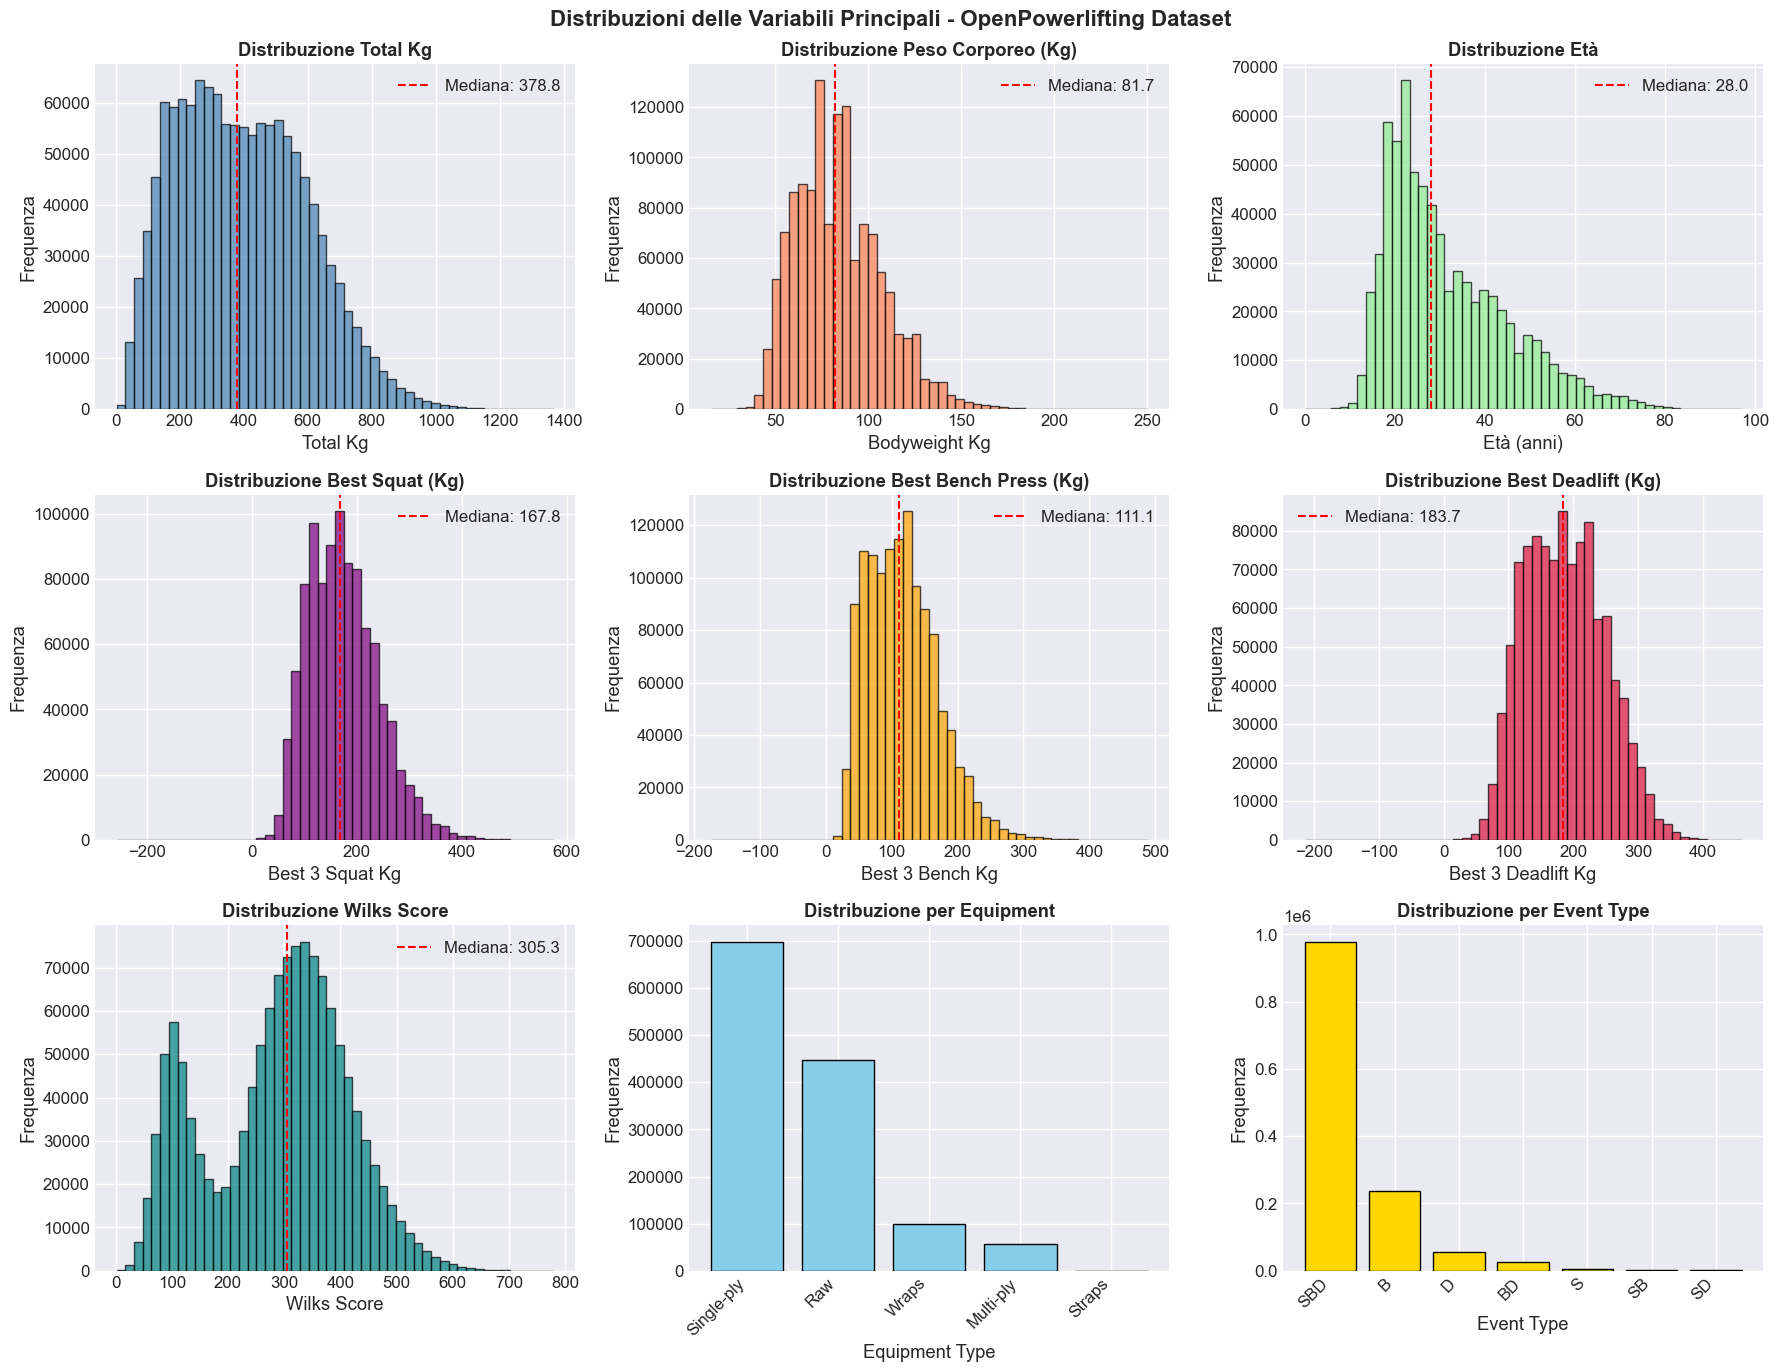


✓ Visualizzazioni create con successo!


In [ ]:
# VISUALIZZAZIONI DELLE DISTRIBUZIONI
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle('Distribuzioni delle Variabili Principali - OpenPowerlifting Dataset', fontsize=16, fontweight='bold')

# 1. Distribuzione TotalKg
axes[0, 0].hist(df_clean['TotalKg'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribuzione Total Kg', fontweight='bold')
axes[0, 0].set_xlabel('Total Kg')
axes[0, 0].set_ylabel('Frequenza')
axes[0, 0].axvline(df_clean['TotalKg'].median(), color='red', linestyle='--', label=f'Mediana: {df_clean["TotalKg"].median():.1f}')
axes[0, 0].legend()

# 2. Distribuzione BodyweightKg
axes[0, 1].hist(df_clean['BodyweightKg'], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribuzione Peso Corporeo (Kg)', fontweight='bold')
axes[0, 1].set_xlabel('Bodyweight Kg')
axes[0, 1].set_ylabel('Frequenza')
axes[0, 1].axvline(df_clean['BodyweightKg'].median(), color='red', linestyle='--', label=f'Mediana: {df_clean["BodyweightKg"].median():.1f}')
axes[0, 1].legend()

# 3. Distribuzione Age
age_data = df_clean[df_clean['Age'].notna()]['Age']
axes[0, 2].hist(age_data, bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[0, 2].set_title('Distribuzione Età', fontweight='bold')
axes[0, 2].set_xlabel('Età (anni)')
axes[0, 2].set_ylabel('Frequenza')
axes[0, 2].axvline(age_data.median(), color='red', linestyle='--', label=f'Mediana: {age_data.median():.1f}')
axes[0, 2].legend()

# 4. Distribuzione Best3SquatKg
squat_data = df_clean[df_clean['Best3SquatKg'].notna()]['Best3SquatKg']
axes[1, 0].hist(squat_data, bins=50, color='purple', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Distribuzione Best Squat (Kg)', fontweight='bold')
axes[1, 0].set_xlabel('Best 3 Squat Kg')
axes[1, 0].set_ylabel('Frequenza')
axes[1, 0].axvline(squat_data.median(), color='red', linestyle='--', label=f'Mediana: {squat_data.median():.1f}')
axes[1, 0].legend()

# 5. Distribuzione Best3BenchKg
bench_data = df_clean[df_clean['Best3BenchKg'].notna()]['Best3BenchKg']
axes[1, 1].hist(bench_data, bins=50, color='orange', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Distribuzione Best Bench Press (Kg)', fontweight='bold')
axes[1, 1].set_xlabel('Best 3 Bench Kg')
axes[1, 1].set_ylabel('Frequenza')
axes[1, 1].axvline(bench_data.median(), color='red', linestyle='--', label=f'Mediana: {bench_data.median():.1f}')
axes[1, 1].legend()

# 6. Distribuzione Best3DeadliftKg
deadlift_data = df_clean[df_clean['Best3DeadliftKg'].notna()]['Best3DeadliftKg']
axes[1, 2].hist(deadlift_data, bins=50, color='crimson', edgecolor='black', alpha=0.7)
axes[1, 2].set_title('Distribuzione Best Deadlift (Kg)', fontweight='bold')
axes[1, 2].set_xlabel('Best 3 Deadlift Kg')
axes[1, 2].set_ylabel('Frequenza')
axes[1, 2].axvline(deadlift_data.median(), color='red', linestyle='--', label=f'Mediana: {deadlift_data.median():.1f}')
axes[1, 2].legend()

# 7. Distribuzione Wilks Score
wilks_data = df_clean[df_clean['Wilks'].notna()]['Wilks']
axes[2, 0].hist(wilks_data, bins=50, color='teal', edgecolor='black', alpha=0.7)
axes[2, 0].set_title('Distribuzione Wilks Score', fontweight='bold')
axes[2, 0].set_xlabel('Wilks Score')
axes[2, 0].set_ylabel('Frequenza')
axes[2, 0].axvline(wilks_data.median(), color='red', linestyle='--', label=f'Mediana: {wilks_data.median():.1f}')
axes[2, 0].legend()

# 8. Distribuzione per Equipment
equipment_counts = df_clean['Equipment'].value_counts()
axes[2, 1].bar(range(len(equipment_counts)), equipment_counts.values, color='skyblue', edgecolor='black')
axes[2, 1].set_title('Distribuzione per Equipment', fontweight='bold')
axes[2, 1].set_xlabel('Equipment Type')
axes[2, 1].set_ylabel('Frequenza')
axes[2, 1].set_xticks(range(len(equipment_counts)))
axes[2, 1].set_xticklabels(equipment_counts.index, rotation=45, ha='right')

# 9. Distribuzione per Event
event_counts = df_clean['Event'].value_counts()
axes[2, 2].bar(range(len(event_counts)), event_counts.values, color='gold', edgecolor='black')
axes[2, 2].set_title('Distribuzione per Event Type', fontweight='bold')
axes[2, 2].set_xlabel('Event Type')
axes[2, 2].set_ylabel('Frequenza')
axes[2, 2].set_xticks(range(len(event_counts)))
axes[2, 2].set_xticklabels(event_counts.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()



BODYWEIGHT vs TOTAL - CLEAN ANALYSIS


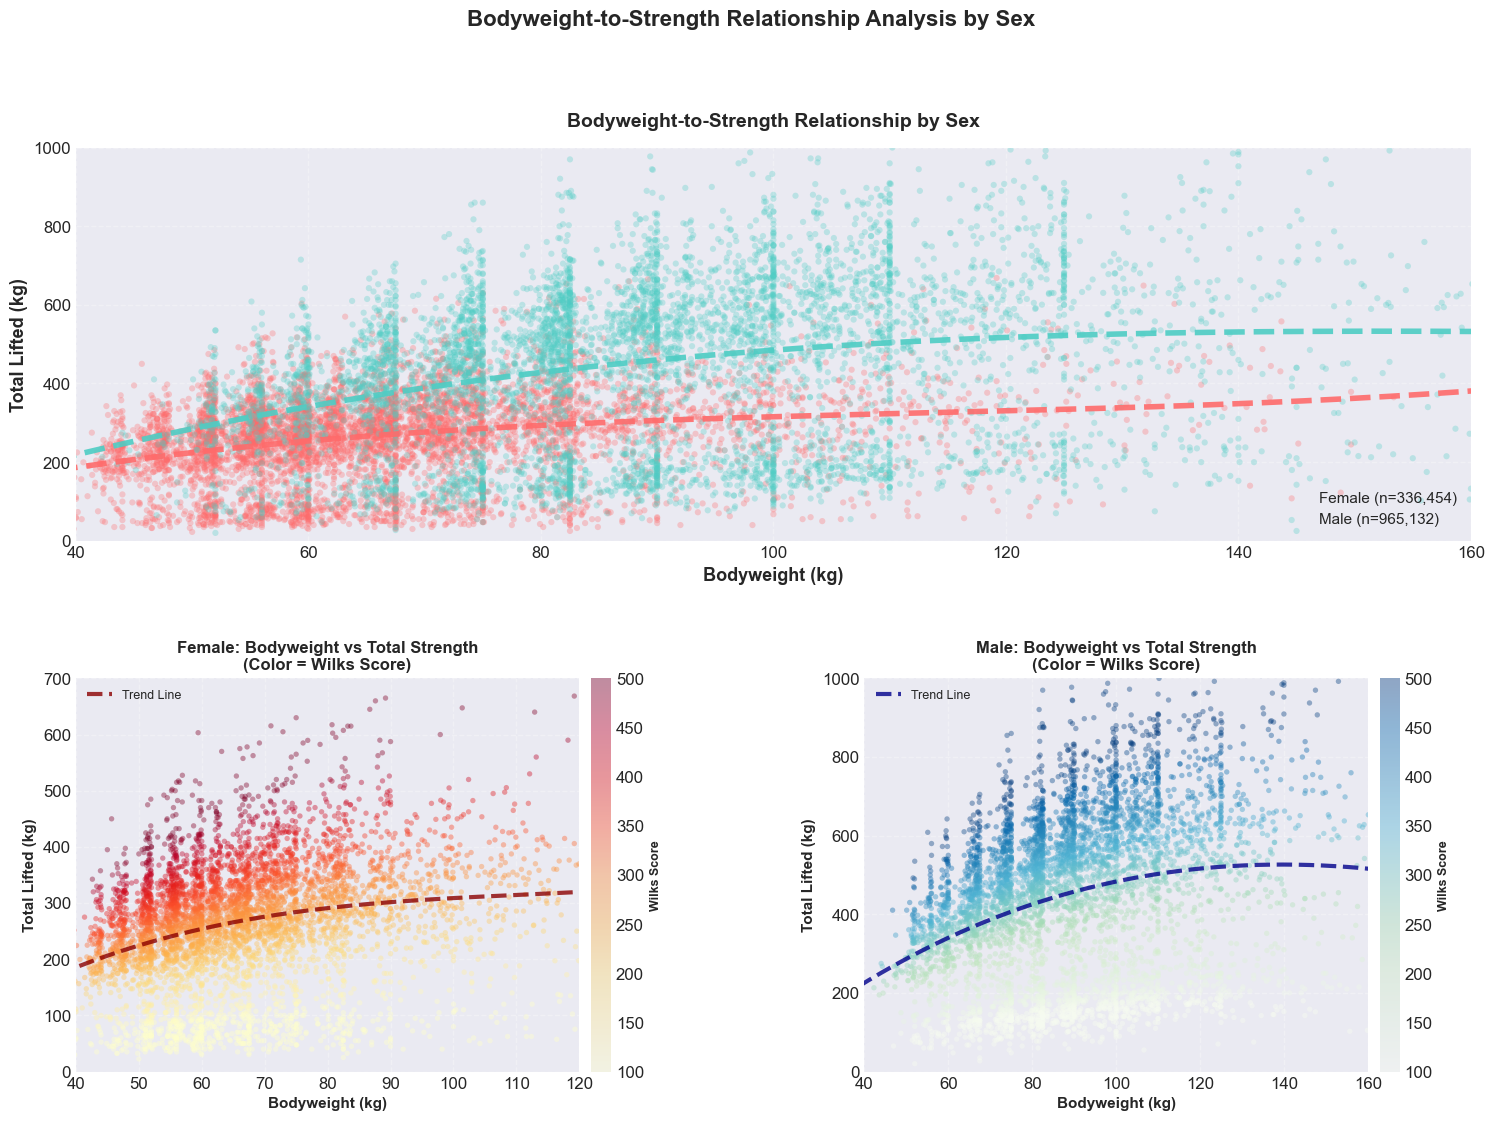

In [56]:
# BODYWEIGHT vs TOTAL - WITHOUT SWEET SPOTS
# Clean visualization

print("=" * 80)
print("BODYWEIGHT vs TOTAL - CLEAN ANALYSIS")
print("=" * 80)

# Prepare data
df_rel = df_clean[['BodyweightKg', 'TotalKg', 'Sex', 'Wilks']].dropna()

# Create figure
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== 1. CLEAR SCATTER PLOT - OVERALL =====
ax1 = fig.add_subplot(gs[0, :])

# Sample data for clarity
sample_size = 6000
for sex, label in [('F', 'Female'), ('M', 'Male')]:
    data_sex = df_rel[df_rel['Sex'] == sex]
    if len(data_sex) > sample_size:
        data_sample = data_sex.sample(n=sample_size, random_state=42)
    else:
        data_sample = data_sex
    
    # Scatter
    ax1.scatter(data_sample['BodyweightKg'], data_sample['TotalKg'], 
               alpha=0.3, s=20, color=colors_sex[sex], edgecolors='none',
               label=f'{label} (n={len(data_sex):,})')

# Add trend curves
from numpy.polynomial import Polynomial

for sex in ['F', 'M']:
    data_sex = df_rel[df_rel['Sex'] == sex].sample(n=min(10000, len(df_rel[df_rel['Sex'] == sex])), 
                                                     random_state=42)
    data_sorted = data_sex.sort_values('BodyweightKg')
    
    p = Polynomial.fit(data_sorted['BodyweightKg'], 
                      data_sorted['TotalKg'], deg=3)
    x_smooth = np.linspace(data_sorted['BodyweightKg'].min(), 
                          data_sorted['BodyweightKg'].max(), 200)
    y_smooth = p(x_smooth)
    
    ax1.plot(x_smooth, y_smooth, color=colors_sex[sex], 
            linewidth=4, linestyle='--', alpha=0.9)

ax1.set_xlabel('Bodyweight (kg)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Total Lifted (kg)', fontsize=13, fontweight='bold')
ax1.set_title('Bodyweight-to-Strength Relationship by Sex', 
             fontsize=14, fontweight='bold', pad=15)
ax1.legend(fontsize=11, loc='lower right', framealpha=0.95)
ax1.grid(alpha=0.3, linestyle='--')
ax1.set_xlim(40, 160)
ax1.set_ylim(0, 1000)

# ===== 2. FEMALE ANALYSIS =====
ax2 = fig.add_subplot(gs[1, 0])

df_f = df_rel[df_rel['Sex'] == 'F'].copy()
sample_f = df_f.sample(n=min(5000, len(df_f)), random_state=42)

# Scatter
scatter_f = ax2.scatter(sample_f['BodyweightKg'], sample_f['TotalKg'],
                       c=sample_f['Wilks'], cmap='YlOrRd', alpha=0.4, s=15,
                       edgecolors='none', vmin=100, vmax=500)

# Trend line
p = Polynomial.fit(sample_f['BodyweightKg'], sample_f['TotalKg'], deg=3)
x_smooth = np.linspace(sample_f['BodyweightKg'].min(), 
                      sample_f['BodyweightKg'].max(), 200)
y_smooth = p(x_smooth)
ax2.plot(x_smooth, y_smooth, color='darkred', linewidth=3, 
        linestyle='--', alpha=0.8, label='Trend Line')

ax2.set_xlabel('Bodyweight (kg)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Total Lifted (kg)', fontsize=11, fontweight='bold')
ax2.set_title('Female: Bodyweight vs Total Strength\n(Color = Wilks Score)', 
             fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(alpha=0.3, linestyle='--')
ax2.set_xlim(40, 120)
ax2.set_ylim(0, 700)

cbar_f = plt.colorbar(scatter_f, ax=ax2, pad=0.02)
cbar_f.set_label('Wilks Score', fontsize=9, fontweight='bold')

# ===== 3. MALE ANALYSIS =====
ax3 = fig.add_subplot(gs[1, 1])

df_m = df_rel[df_rel['Sex'] == 'M'].copy()
sample_m = df_m.sample(n=min(5000, len(df_m)), random_state=42)

# Scatter
scatter_m = ax3.scatter(sample_m['BodyweightKg'], sample_m['TotalKg'],
                       c=sample_m['Wilks'], cmap='GnBu', alpha=0.4, s=15,
                       edgecolors='none', vmin=100, vmax=500)

# Trend line
p = Polynomial.fit(sample_m['BodyweightKg'], sample_m['TotalKg'], deg=3)
x_smooth = np.linspace(sample_m['BodyweightKg'].min(), 
                      sample_m['BodyweightKg'].max(), 200)
y_smooth = p(x_smooth)
ax3.plot(x_smooth, y_smooth, color='darkblue', linewidth=3, 
        linestyle='--', alpha=0.8, label='Trend Line')

ax3.set_xlabel('Bodyweight (kg)', fontsize=11, fontweight='bold')
ax3.set_ylabel('Total Lifted (kg)', fontsize=11, fontweight='bold')
ax3.set_title('Male: Bodyweight vs Total Strength\n(Color = Wilks Score)', 
             fontsize=12, fontweight='bold')
ax3.legend(fontsize=9, loc='upper left')
ax3.grid(alpha=0.3, linestyle='--')
ax3.set_xlim(40, 160)
ax3.set_ylim(0, 1000)

cbar_m = plt.colorbar(scatter_m, ax=ax3, pad=0.02)
cbar_m.set_label('Wilks Score', fontsize=9, fontweight='bold')

plt.suptitle('Bodyweight-to-Strength Relationship Analysis by Sex', 
            fontsize=16, fontweight='bold', y=0.995)

plt.tight_layout()
plt.show()


In [76]:
# ============================================================================
# VISUALIZATION 1: Distribution of Powerlifters by Weight Class
# Based on: "Distribution of Powerlifters by Weight Class" article
# ============================================================================

print("=" * 80)
print("VISUALIZATION 1: Distribution of Powerlifters by Weight Class")
print("=" * 80)

# Prepare data
df_viz1 = df_clean[df_clean['WeightClassKg'].notna()].copy()

# Standardize weight classes - extract numeric values
def extract_weight_class(weight_str):
    """Extract numeric weight class value"""
    if pd.isna(weight_str):
        return None
    weight_str = str(weight_str).lower().replace('kg', '').strip()
    if '+' in weight_str:
        return float(weight_str.replace('+', ''))
    elif '-' in weight_str:
        return float(weight_str.split('-')[1])
    else:
        try:
            return float(weight_str)
        except:
            return None

df_viz1['WeightClassNumeric'] = df_viz1['WeightClassKg'].apply(extract_weight_class)
df_viz1 = df_viz1[df_viz1['WeightClassNumeric'].notna()]

# Get top weight classes by participation
top_weight_classes = df_viz1['WeightClassKg'].value_counts().head(15).index.tolist()
df_viz1_filtered = df_viz1[df_viz1['WeightClassKg'].isin(top_weight_classes)]

# Calculate counts by weight class and sex
weight_class_stats = df_viz1_filtered.groupby(['WeightClassKg', 'Sex']).size().reset_index(name='Count')

# Sort weight classes by numeric value
weight_class_order = sorted(top_weight_classes, key=lambda x: extract_weight_class(x) or 0)

# Create visualization
fig, ax = plt.subplots(figsize=(16, 8))
colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

x_pos = np.arange(len(weight_class_order))
width = 0.35

for i, sex in enumerate(['F', 'M']):
    counts = []
    for wc in weight_class_order:
        count = weight_class_stats[(weight_class_stats['WeightClassKg'] == wc) & 
                                   (weight_class_stats['Sex'] == sex)]['Count'].values
        counts.append(count[0] if len(count) > 0 else 0)
    
    offset = width * (i - 0.5)
    bars = ax.bar(x_pos + offset, counts, width, label='Female' if sex == 'F' else 'Male',
                 color=colors_sex[sex], alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{int(height):,}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Weight Class (kg)', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Lifters', fontsize=13, fontweight='bold')
ax.set_title('Distribution of Powerlifters by Weight Class', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x_pos)
ax.set_xticklabels(weight_class_order, rotation=45, ha='right', fontsize=10)
ax.legend(fontsize=12, framealpha=0.9)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print(f"\nTotal lifters analyzed: {len(df_viz1_filtered):,}")
print(f"Weight classes shown: {len(weight_class_order)}")
print(f"\nTop 3 weight classes:")
for i, wc in enumerate(weight_class_order[:3], 1):
    total = weight_class_stats[weight_class_stats['WeightClassKg'] == wc]['Count'].sum()
    print(f"  {i}. {wc}: {total:,} lifters")


VISUALIZATION 1: Distribution of Powerlifters by Weight Class


ValueError: could not convert string to float: ''

VISUALIZATION 2: 10-Year Growth - Maximum Totals AND Median Performance


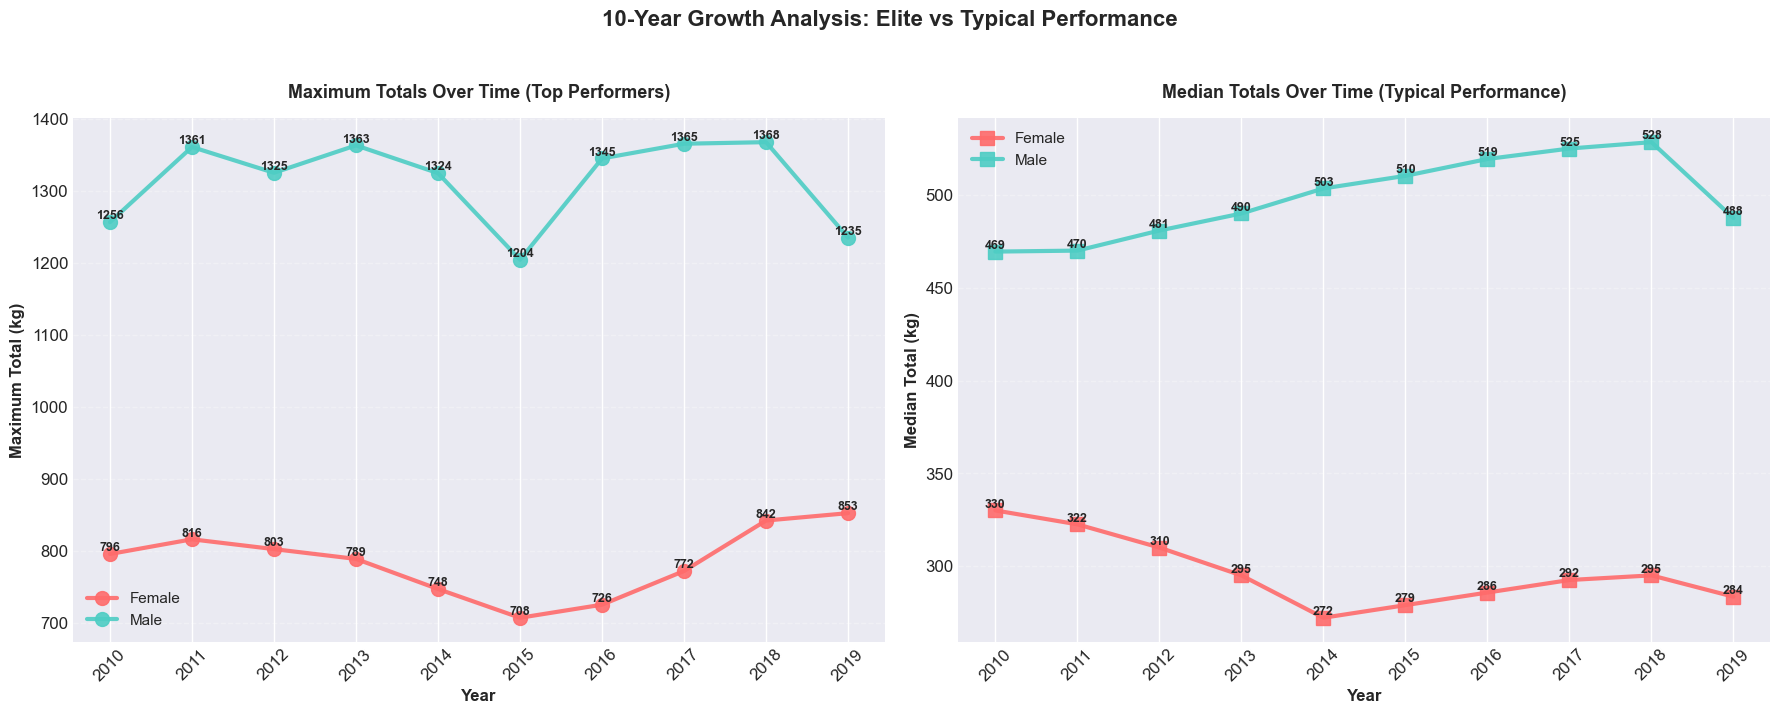


Growth Statistics:

Female:
  Max Total Growth: 7.12% (796kg → 853kg)
  Median Total Growth: -14.09% (330kg → 284kg)

Male:
  Max Total Growth: -1.71% (1256kg → 1235kg)
  Median Total Growth: 3.84% (469kg → 488kg)


In [77]:
# ============================================================================
# VISUALIZATION 2: 10-Year Growth - Maximum Totals AND Median Performance
# Inspired by: "10 year Growth of Highest Totals" article (enhanced version)
# ============================================================================

print("=" * 80)
print("VISUALIZATION 2: 10-Year Growth - Maximum Totals AND Median Performance")
print("=" * 80)

# Prepare data - last 10 years
current_year = df_clean['Year'].max()
start_year = current_year - 9  # Last 10 years inclusive
df_viz2 = df_clean[(df_clean['Year'] >= start_year) & (df_clean['Year'] <= current_year)].copy()
df_viz2 = df_viz2[df_viz2['Year'].notna()]

# Calculate maximum and median totals by year and sex
yearly_stats = df_viz2.groupby(['Year', 'Sex']).agg({
    'TotalKg': ['max', 'median']
}).reset_index()
yearly_stats.columns = ['Year', 'Sex', 'MaxTotalKg', 'MedianTotalKg']

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== LEFT PANEL: Maximum Totals =====
ax1 = axes[0]

for sex in ['F', 'M']:
    data = yearly_stats[yearly_stats['Sex'] == sex].sort_values('Year')
    ax1.plot(data['Year'], data['MaxTotalKg'], 
            marker='o', markersize=10, linewidth=3, 
            label='Female' if sex == 'F' else 'Male',
            color=colors_sex[sex], alpha=0.9)
    
    # Add value labels
    for _, row in data.iterrows():
        ax1.text(row['Year'], row['MaxTotalKg'], 
                f"{row['MaxTotalKg']:.0f}", 
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Total (kg)', fontsize=12, fontweight='bold')
ax1.set_title('Maximum Totals Over Time (Top Performers)', fontsize=13, fontweight='bold', pad=15)
ax1.legend(fontsize=11, framealpha=0.9, loc='best')
ax1.grid(alpha=0.3, linestyle='--', axis='y')
ax1.set_xticks(yearly_stats['Year'].unique())
ax1.tick_params(axis='x', rotation=45)

# ===== RIGHT PANEL: Median Totals =====
ax2 = axes[1]

for sex in ['F', 'M']:
    data = yearly_stats[yearly_stats['Sex'] == sex].sort_values('Year')
    ax2.plot(data['Year'], data['MedianTotalKg'], 
            marker='s', markersize=10, linewidth=3, 
            label='Female' if sex == 'F' else 'Male',
            color=colors_sex[sex], alpha=0.9)
    
    # Add value labels
    for _, row in data.iterrows():
        ax2.text(row['Year'], row['MedianTotalKg'], 
                f"{row['MedianTotalKg']:.0f}", 
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_xlabel('Year', fontsize=12, fontweight='bold')
ax2.set_ylabel('Median Total (kg)', fontsize=12, fontweight='bold')
ax2.set_title('Median Totals Over Time (Typical Performance)', fontsize=13, fontweight='bold', pad=15)
ax2.legend(fontsize=11, framealpha=0.9, loc='best')
ax2.grid(alpha=0.3, linestyle='--', axis='y')
ax2.set_xticks(yearly_stats['Year'].unique())
ax2.tick_params(axis='x', rotation=45)

plt.suptitle('10-Year Growth Analysis: Elite vs Typical Performance', 
            fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print growth statistics
print("\nGrowth Statistics:")
for sex in ['F', 'M']:
    data = yearly_stats[yearly_stats['Sex'] == sex].sort_values('Year')
    max_growth = ((data['MaxTotalKg'].iloc[-1] - data['MaxTotalKg'].iloc[0]) / data['MaxTotalKg'].iloc[0]) * 100
    median_growth = ((data['MedianTotalKg'].iloc[-1] - data['MedianTotalKg'].iloc[0]) / data['MedianTotalKg'].iloc[0]) * 100
    sex_label = 'Female' if sex == 'F' else 'Male'
    print(f"\n{sex_label}:")
    print(f"  Max Total Growth: {max_growth:.2f}% ({data['MaxTotalKg'].iloc[0]:.0f}kg → {data['MaxTotalKg'].iloc[-1]:.0f}kg)")
    print(f"  Median Total Growth: {median_growth:.2f}% ({data['MedianTotalKg'].iloc[0]:.0f}kg → {data['MedianTotalKg'].iloc[-1]:.0f}kg)")


VISUALIZATION 3: Squat Contribution to Total for Heavier and Elite Lifters


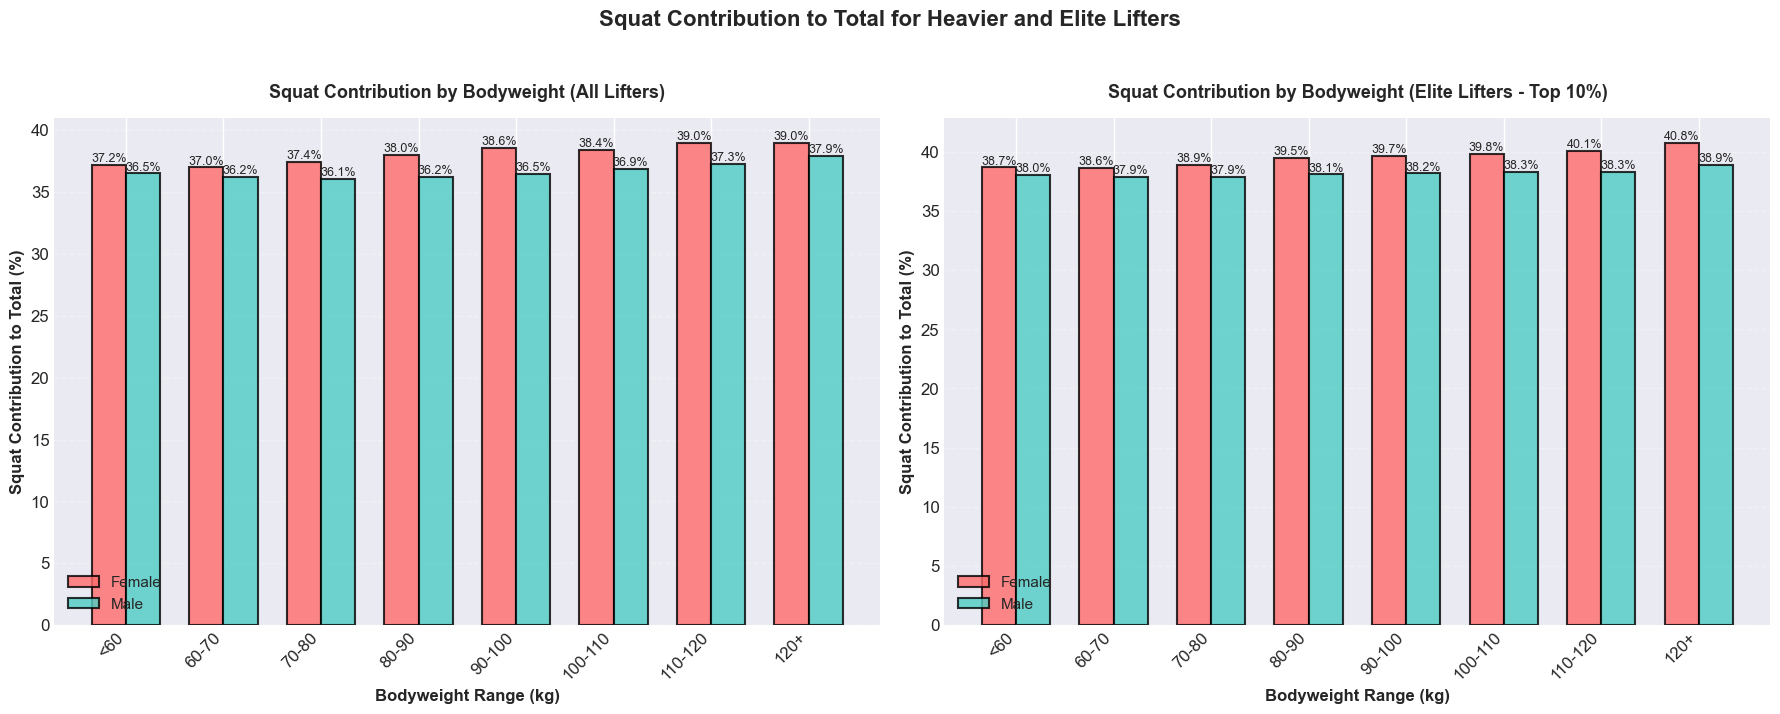


Total lifters analyzed: 978,692
Elite threshold (Wilks): 453.79
Elite lifters: 97,889 (10.0%)


In [78]:
# ============================================================================
# VISUALIZATION 3: Squat Contribution to Total for Heavier and Elite Lifters
# Based on: "Squat Contributes More to Total for Heavier and Elite Lifters" article
# ============================================================================

print("=" * 80)
print("VISUALIZATION 3: Squat Contribution to Total for Heavier and Elite Lifters")
print("=" * 80)

# Prepare data
df_viz3 = df_clean[
    (df_clean['Best3SquatKg'].notna()) & 
    (df_clean['TotalKg'].notna())
].copy()

# Calculate squat percentage
df_viz3['SquatPct'] = (df_viz3['Best3SquatKg'] / df_viz3['TotalKg']) * 100

# Create bodyweight bins
df_viz3['BodyweightBin'] = pd.cut(df_viz3['BodyweightKg'], 
                                  bins=[0, 60, 70, 80, 90, 100, 110, 120, 200],
                                  labels=['<60', '60-70', '70-80', '80-90', '90-100', '100-110', '110-120', '120+'])

# Define elite status (top 10% by Wilks)
df_viz3 = df_viz3[df_viz3['Wilks'].notna()]
wilks_threshold = df_viz3['Wilks'].quantile(0.90)
df_viz3['IsElite'] = df_viz3['Wilks'] >= wilks_threshold

# Calculate average squat contribution by bodyweight bin and elite status
contribution_stats = df_viz3.groupby(['BodyweightBin', 'IsElite', 'Sex']).agg({
    'SquatPct': 'mean'
}).reset_index()

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== LEFT PANEL: All Lifters =====
ax1 = axes[0]
bodyweight_bins = ['<60', '60-70', '70-80', '80-90', '90-100', '100-110', '110-120', '120+']
x_pos = np.arange(len(bodyweight_bins))
width = 0.35

for i, sex in enumerate(['F', 'M']):
    data_all = contribution_stats[(contribution_stats['Sex'] == sex) & 
                                  (contribution_stats['IsElite'] == False)]
    
    squat_pct = []
    for bin_label in bodyweight_bins:
        bin_data = data_all[data_all['BodyweightBin'] == bin_label]
        squat_pct.append(bin_data['SquatPct'].iloc[0] if len(bin_data) > 0 else 0)
    
    offset = width * (i - 0.5)
    bars = ax1.bar(x_pos + offset, squat_pct, width, 
                   label='Female' if sex == 'F' else 'Male',
                   color=colors_sex[sex], alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax1.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

ax1.set_xlabel('Bodyweight Range (kg)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Squat Contribution to Total (%)', fontsize=12, fontweight='bold')
ax1.set_title('Squat Contribution by Bodyweight (All Lifters)', fontsize=13, fontweight='bold', pad=15)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(bodyweight_bins, rotation=45, ha='right')
ax1.legend(fontsize=11, framealpha=0.9)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# ===== RIGHT PANEL: Elite Lifters =====
ax2 = axes[1]

for i, sex in enumerate(['F', 'M']):
    data_elite = contribution_stats[(contribution_stats['Sex'] == sex) & 
                                    (contribution_stats['IsElite'] == True)]
    
    squat_pct = []
    for bin_label in bodyweight_bins:
        bin_data = data_elite[data_elite['BodyweightBin'] == bin_label]
        squat_pct.append(bin_data['SquatPct'].iloc[0] if len(bin_data) > 0 else 0)
    
    offset = width * (i - 0.5)
    bars = ax2.bar(x_pos + offset, squat_pct, width, 
                   label='Female' if sex == 'F' else 'Male',
                   color=colors_sex[sex], alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax2.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

ax2.set_xlabel('Bodyweight Range (kg)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Squat Contribution to Total (%)', fontsize=12, fontweight='bold')
ax2.set_title('Squat Contribution by Bodyweight (Elite Lifters - Top 10%)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(bodyweight_bins, rotation=45, ha='right')
ax2.legend(fontsize=11, framealpha=0.9)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle('Squat Contribution to Total for Heavier and Elite Lifters', 
            fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nTotal lifters analyzed: {len(df_viz3):,}")
print(f"Elite threshold (Wilks): {wilks_threshold:.2f}")
print(f"Elite lifters: {(df_viz3['IsElite'] == True).sum():,} ({(df_viz3['IsElite'] == True).sum() / len(df_viz3) * 100:.1f}%)")


VISUALIZATION 4: Powerlifters Going 9/9 Are More Likely to Win


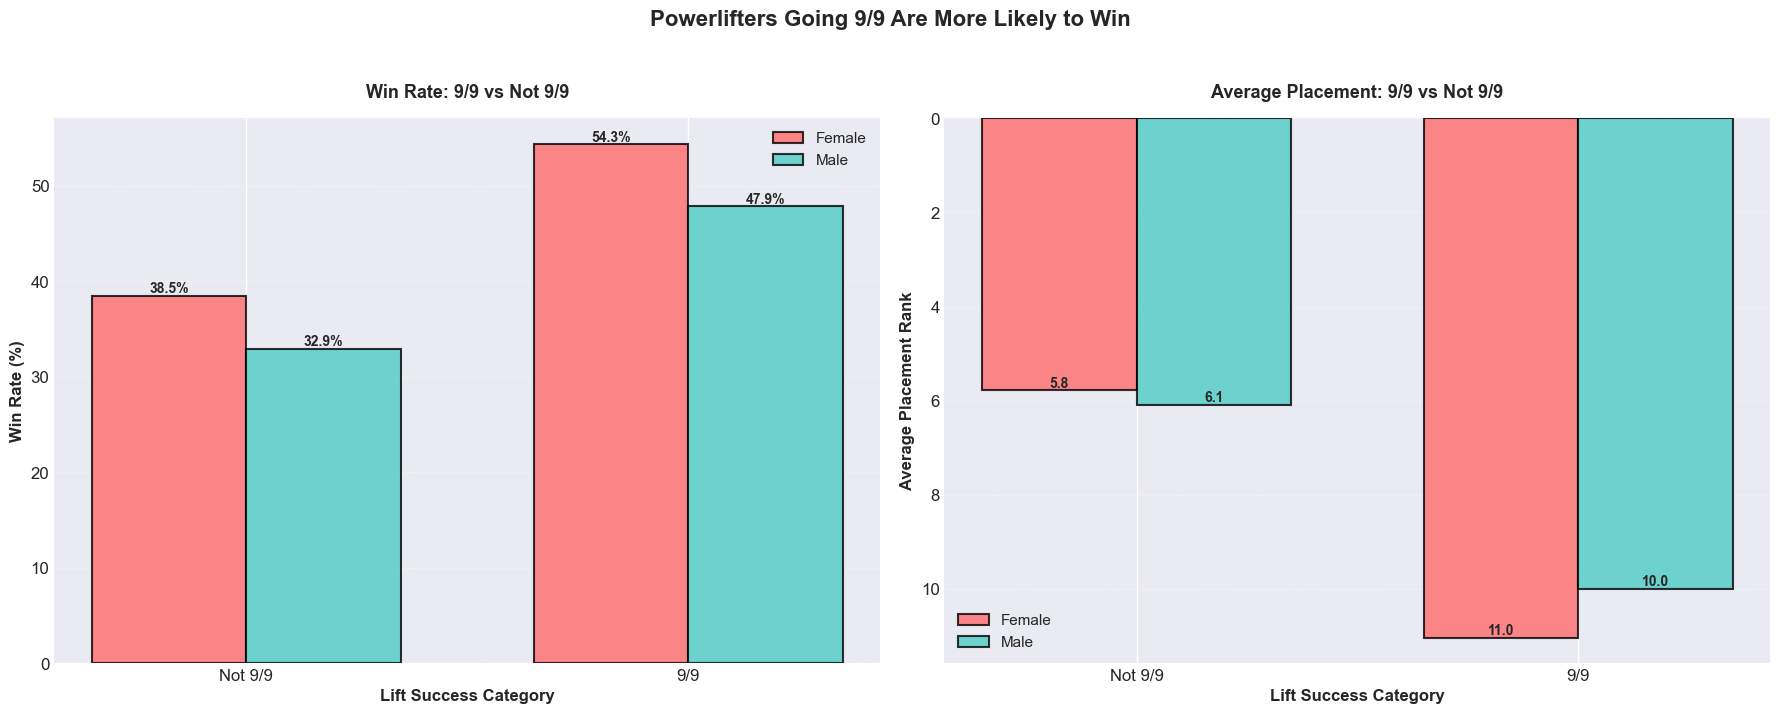


Success Statistics:

Female:
  Not 9/9: 38.47% win rate, avg placement 5.8 (n=263,416)
  9/9: 54.34% win rate, avg placement 11.0 (n=10,899)
  Improvement: 41.3% increase in win rate for 9/9 lifters

Male:
  Not 9/9: 32.93% win rate, avg placement 6.1 (n=681,897)
  9/9: 47.85% win rate, avg placement 10.0 (n=23,298)
  Improvement: 45.3% increase in win rate for 9/9 lifters


In [80]:
# ============================================================================
# VISUALIZATION 4: Powerlifters Going 9/9 Are More Likely to Win
# Based on: "Powerlifters That Go 9/9 Are 32% More Likely To Win" article
# ============================================================================

print("=" * 80)
print("VISUALIZATION 4: Powerlifters Going 9/9 Are More Likely to Win")
print("=" * 80)

# Prepare data - need all 9 lift attempts
df_viz4 = df_clean.copy()

# Count successful lifts (not null and > 0)
lift_columns = ['Squat1Kg', 'Squat2Kg', 'Squat3Kg', 
                'Bench1Kg', 'Bench2Kg', 'Bench3Kg',
                'Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg']

df_viz4['SuccessfulLifts'] = 0
for col in lift_columns:
    df_viz4['SuccessfulLifts'] += (df_viz4[col].notna() & (df_viz4[col] > 0)).astype(int)

# Create 9/9 flag
df_viz4['Is9for9'] = df_viz4['SuccessfulLifts'] == 9

# Convert Place to numeric (1 = win)
def parse_place(place_str):
    """Convert place string to numeric rank"""
    if pd.isna(place_str):
        return None
    place_str = str(place_str).strip()
    if place_str.isdigit():
        return int(place_str)
    elif place_str.upper() in ['DQ', 'DD', 'NS']:
        return 999
    else:
        try:
            return int(''.join(filter(str.isdigit, place_str)) or 999)
        except:
            return 999






















            

df_viz4['PlaceNumeric'] = df_viz4['Place'].apply(parse_place)
df_viz4 = df_viz4[df_viz4['PlaceNumeric'].notna()]

# Calculate win rate by 9/9 status
success_stats = df_viz4.groupby(['Is9for9', 'Sex']).agg({
    'PlaceNumeric': ['count', lambda x: (x == 1).sum(), 'mean']
}).reset_index()
success_stats.columns = ['Is9for9', 'Sex', 'TotalCompetitors', 'Wins', 'AvgPlace']
success_stats['WinRate'] = (success_stats['Wins'] / success_stats['TotalCompetitors']) * 100
success_stats['Category'] = success_stats['Is9for9'].apply(lambda x: '9/9' if x else 'Not 9/9')

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== LEFT PANEL: Win Rate Comparison =====
ax1 = axes[0]
x_pos = np.arange(2)  # 9/9 and Not 9/9
width = 0.35

for i, sex in enumerate(['F', 'M']):
    data = success_stats[success_stats['Sex'] == sex].sort_values('Is9for9')
    win_rates = []
    categories = []
    for _, row in data.iterrows():
        win_rates.append(row['WinRate'])
        categories.append(row['Category'])
    
    offset = width * (i - 0.5)
    bars = ax1.bar(x_pos + offset, win_rates, width, 
                   label='Female' if sex == 'F' else 'Male',
                   color=colors_sex[sex], alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar, rate in zip(bars, win_rates):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_xlabel('Lift Success Category', fontsize=12, fontweight='bold')
ax1.set_ylabel('Win Rate (%)', fontsize=12, fontweight='bold')
ax1.set_title('Win Rate: 9/9 vs Not 9/9', fontsize=13, fontweight='bold', pad=15)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(['Not 9/9', '9/9'])
ax1.legend(fontsize=11, framealpha=0.9)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# ===== RIGHT PANEL: Average Placement Comparison =====
ax2 = axes[1]

for i, sex in enumerate(['F', 'M']):
    data = success_stats[success_stats['Sex'] == sex].sort_values('Is9for9')
    avg_places = []
    for _, row in data.iterrows():
        avg_places.append(row['AvgPlace'])
    
    offset = width * (i - 0.5)
    bars = ax2.bar(x_pos + offset, avg_places, width, 
                   label='Female' if sex == 'F' else 'Male',
                   color=colors_sex[sex], alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar, place in zip(bars, avg_places):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{place:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.set_xlabel('Lift Success Category', fontsize=12, fontweight='bold')
ax2.set_ylabel('Average Placement Rank', fontsize=12, fontweight='bold')
ax2.set_title('Average Placement: 9/9 vs Not 9/9', fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(['Not 9/9', '9/9'])
ax2.legend(fontsize=11, framealpha=0.9)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.invert_yaxis()

plt.suptitle('Powerlifters Going 9/9 Are More Likely to Win', 
            fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print statistics
print("\nSuccess Statistics:")
for sex in ['F', 'M']:
    data = success_stats[success_stats['Sex'] == sex].sort_values('Is9for9')
    sex_label = 'Female' if sex == 'F' else 'Male'
    print(f"\n{sex_label}:")
    for _, row in data.iterrows():
        print(f"  {row['Category']}: {row['WinRate']:.2f}% win rate, "
              f"avg placement {row['AvgPlace']:.1f} (n={int(row['TotalCompetitors']):,})")
    
    # Calculate improvement
    if len(data) == 2:
        not_9_9 = data[data['Is9for9'] == False]['WinRate'].iloc[0]
        is_9_9 = data[data['Is9for9'] == True]['WinRate'].iloc[0]
        if not_9_9 > 0:
            improvement = ((is_9_9 - not_9_9) / not_9_9) * 100
            print(f"  Improvement: {improvement:.1f}% increase in win rate for 9/9 lifters")


VISUALIZATION 5: Age-Performance Relationship - Peak Analysis


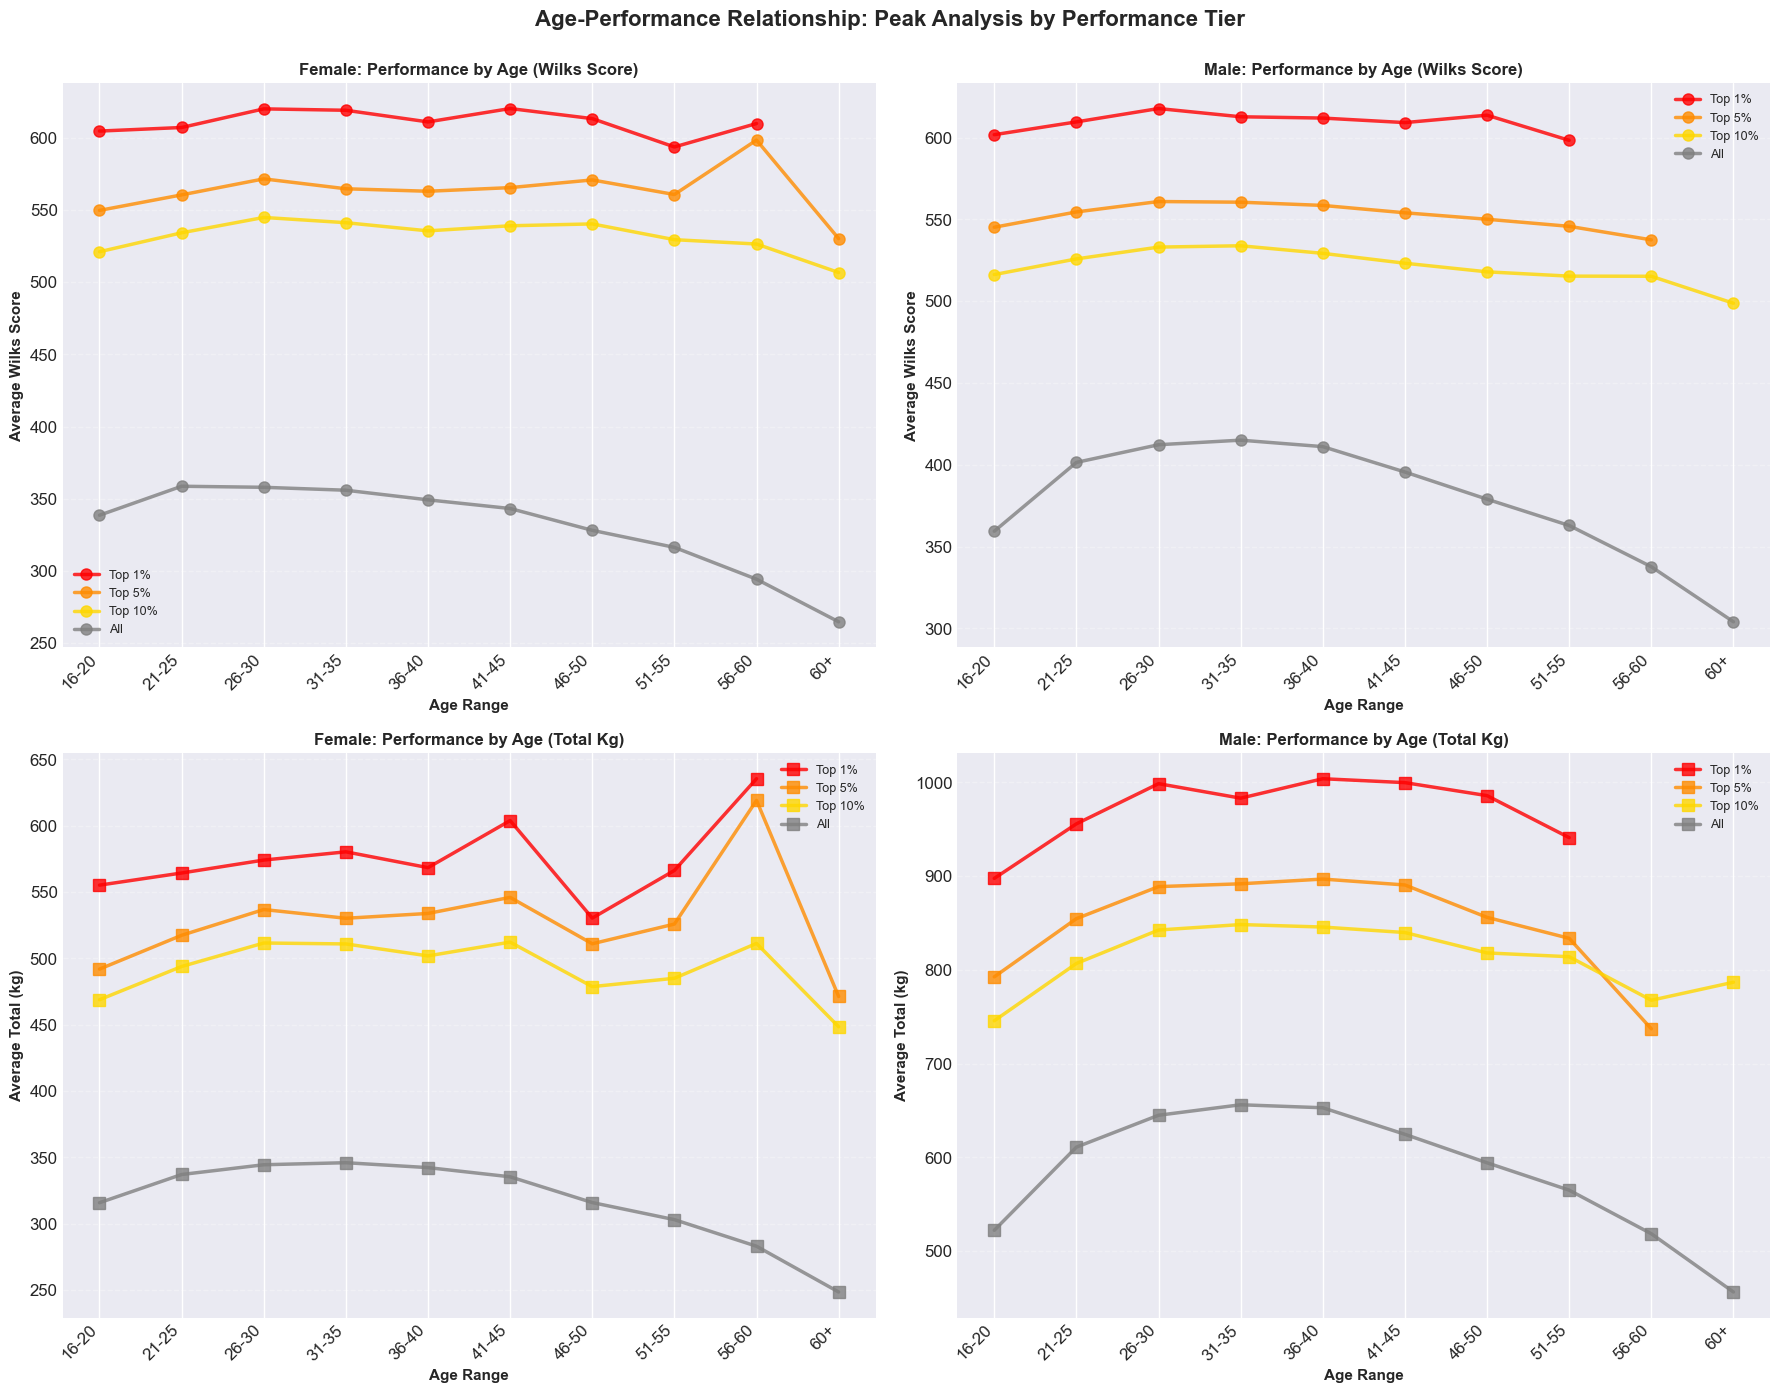


Peak Age Analysis (by Wilks Score):

Female:
  Top 1%: Peak at 41-45 (Wilks: 620.4)
  Top 5%: Peak at 56-60 (Wilks: 598.5)
  Top 10%: Peak at 26-30 (Wilks: 544.9)

Male:
  Top 1%: Peak at 26-30 (Wilks: 617.8)
  Top 5%: Peak at 26-30 (Wilks: 560.9)
  Top 10%: Peak at 31-35 (Wilks: 533.9)


In [81]:
# ============================================================================
# VISUALIZATION 5: Age-Performance Relationship - Peak Analysis
# Inspired by: "Elite Powerlifters Peak at Age 30" article
# ============================================================================

print("=" * 80)
print("VISUALIZATION 5: Age-Performance Relationship - Peak Analysis")
print("=" * 80)

# Prepare data
df_viz5 = df_clean[(df_clean['Age'].notna()) & (df_clean['Wilks'].notna())].copy()
df_viz5 = df_viz5[(df_viz5['Age'] >= 16) & (df_viz5['Age'] <= 70)]  # Reasonable age range

# Create age bins
df_viz5['AgeBin'] = pd.cut(df_viz5['Age'], 
                           bins=[16, 20, 25, 30, 35, 40, 45, 50, 55, 60, 70],
                           labels=['16-20', '21-25', '26-30', '31-35', '36-40', '41-45', '46-50', '51-55', '56-60', '60+'])

# Define performance tiers
df_viz5['IsTop1'] = df_viz5['Wilks'] >= df_viz5['Wilks'].quantile(0.99)
df_viz5['IsTop5'] = df_viz5['Wilks'] >= df_viz5['Wilks'].quantile(0.95)
df_viz5['IsTop10'] = df_viz5['Wilks'] >= df_viz5['Wilks'].quantile(0.90)

# Calculate average performance by age bin and tier
age_performance = []
for tier_name, tier_col in [('Top 1%', 'IsTop1'), ('Top 5%', 'IsTop5'), ('Top 10%', 'IsTop10'), ('All', None)]:
    if tier_col:
        tier_data = df_viz5[df_viz5[tier_col] == True]
    else:
        tier_data = df_viz5
    
    for sex in ['F', 'M']:
        sex_data = tier_data[tier_data['Sex'] == sex]
        age_stats = sex_data.groupby('AgeBin').agg({
            'Wilks': 'mean',
            'TotalKg': 'mean',
            'Age': 'count'
        }).reset_index()
        age_stats.columns = ['AgeBin', 'AvgWilks', 'AvgTotalKg', 'Count']
        age_stats['Tier'] = tier_name
        age_stats['Sex'] = sex
        age_performance.append(age_stats)

age_perf_df = pd.concat(age_performance, ignore_index=True)

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}
tier_colors = {'Top 1%': '#FF0000', 'Top 5%': '#FF8C00', 'Top 10%': '#FFD700', 'All': '#808080'}
age_bins = ['16-20', '21-25', '26-30', '31-35', '36-40', '41-45', '46-50', '51-55', '56-60', '60+']
x_pos = np.arange(len(age_bins))

# ===== TOP LEFT: Female - Wilks by Tier =====
ax1 = axes[0, 0]
for tier in ['Top 1%', 'Top 5%', 'Top 10%', 'All']:
    data = age_perf_df[(age_perf_df['Sex'] == 'F') & (age_perf_df['Tier'] == tier)]
    wilks_values = []
    for bin_label in age_bins:
        bin_data = data[data['AgeBin'] == bin_label]
        wilks_values.append(bin_data['AvgWilks'].iloc[0] if len(bin_data) > 0 else np.nan)
    
    ax1.plot(x_pos, wilks_values, marker='o', markersize=8, linewidth=2.5,
            label=tier, color=tier_colors[tier], alpha=0.8)

ax1.set_xlabel('Age Range', fontsize=11, fontweight='bold')
ax1.set_ylabel('Average Wilks Score', fontsize=11, fontweight='bold')
ax1.set_title('Female: Performance by Age (Wilks Score)', fontsize=12, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(age_bins, rotation=45, ha='right')
ax1.legend(fontsize=9, framealpha=0.9)
ax1.grid(alpha=0.3, linestyle='--', axis='y')

# ===== TOP RIGHT: Male - Wilks by Tier =====
ax2 = axes[0, 1]
for tier in ['Top 1%', 'Top 5%', 'Top 10%', 'All']:
    data = age_perf_df[(age_perf_df['Sex'] == 'M') & (age_perf_df['Tier'] == tier)]
    wilks_values = []
    for bin_label in age_bins:
        bin_data = data[data['AgeBin'] == bin_label]
        wilks_values.append(bin_data['AvgWilks'].iloc[0] if len(bin_data) > 0 else np.nan)
    
    ax2.plot(x_pos, wilks_values, marker='o', markersize=8, linewidth=2.5,
            label=tier, color=tier_colors[tier], alpha=0.8)

ax2.set_xlabel('Age Range', fontsize=11, fontweight='bold')
ax2.set_ylabel('Average Wilks Score', fontsize=11, fontweight='bold')
ax2.set_title('Male: Performance by Age (Wilks Score)', fontsize=12, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(age_bins, rotation=45, ha='right')
ax2.legend(fontsize=9, framealpha=0.9)
ax2.grid(alpha=0.3, linestyle='--', axis='y')

# ===== BOTTOM LEFT: Female - TotalKg by Tier =====
ax3 = axes[1, 0]
for tier in ['Top 1%', 'Top 5%', 'Top 10%', 'All']:
    data = age_perf_df[(age_perf_df['Sex'] == 'F') & (age_perf_df['Tier'] == tier)]
    total_values = []
    for bin_label in age_bins:
        bin_data = data[data['AgeBin'] == bin_label]
        total_values.append(bin_data['AvgTotalKg'].iloc[0] if len(bin_data) > 0 else np.nan)
    
    ax3.plot(x_pos, total_values, marker='s', markersize=8, linewidth=2.5,
            label=tier, color=tier_colors[tier], alpha=0.8)

ax3.set_xlabel('Age Range', fontsize=11, fontweight='bold')
ax3.set_ylabel('Average Total (kg)', fontsize=11, fontweight='bold')
ax3.set_title('Female: Performance by Age (Total Kg)', fontsize=12, fontweight='bold')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(age_bins, rotation=45, ha='right')
ax3.legend(fontsize=9, framealpha=0.9)
ax3.grid(alpha=0.3, linestyle='--', axis='y')

# ===== BOTTOM RIGHT: Male - TotalKg by Tier =====
ax4 = axes[1, 1]
for tier in ['Top 1%', 'Top 5%', 'Top 10%', 'All']:
    data = age_perf_df[(age_perf_df['Sex'] == 'M') & (age_perf_df['Tier'] == tier)]
    total_values = []
    for bin_label in age_bins:
        bin_data = data[data['AgeBin'] == bin_label]
        total_values.append(bin_data['AvgTotalKg'].iloc[0] if len(bin_data) > 0 else np.nan)
    
    ax4.plot(x_pos, total_values, marker='s', markersize=8, linewidth=2.5,
            label=tier, color=tier_colors[tier], alpha=0.8)

ax4.set_xlabel('Age Range', fontsize=11, fontweight='bold')
ax4.set_ylabel('Average Total (kg)', fontsize=11, fontweight='bold')
ax4.set_title('Male: Performance by Age (Total Kg)', fontsize=12, fontweight='bold')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(age_bins, rotation=45, ha='right')
ax4.legend(fontsize=9, framealpha=0.9)
ax4.grid(alpha=0.3, linestyle='--', axis='y')

plt.suptitle('Age-Performance Relationship: Peak Analysis by Performance Tier', 
            fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# Find peak ages
print("\nPeak Age Analysis (by Wilks Score):")
for sex in ['F', 'M']:
    sex_label = 'Female' if sex == 'F' else 'Male'
    print(f"\n{sex_label}:")
    for tier in ['Top 1%', 'Top 5%', 'Top 10%']:
        data = age_perf_df[(age_perf_df['Sex'] == sex) & (age_perf_df['Tier'] == tier)]
        if len(data) > 0:
            peak_idx = data['AvgWilks'].idxmax()
            peak_age = data.loc[peak_idx, 'AgeBin']
            peak_wilks = data.loc[peak_idx, 'AvgWilks']
            print(f"  {tier}: Peak at {peak_age} (Wilks: {peak_wilks:.1f})")


VISUALIZATION 6: Regional Growth and Participation Trends


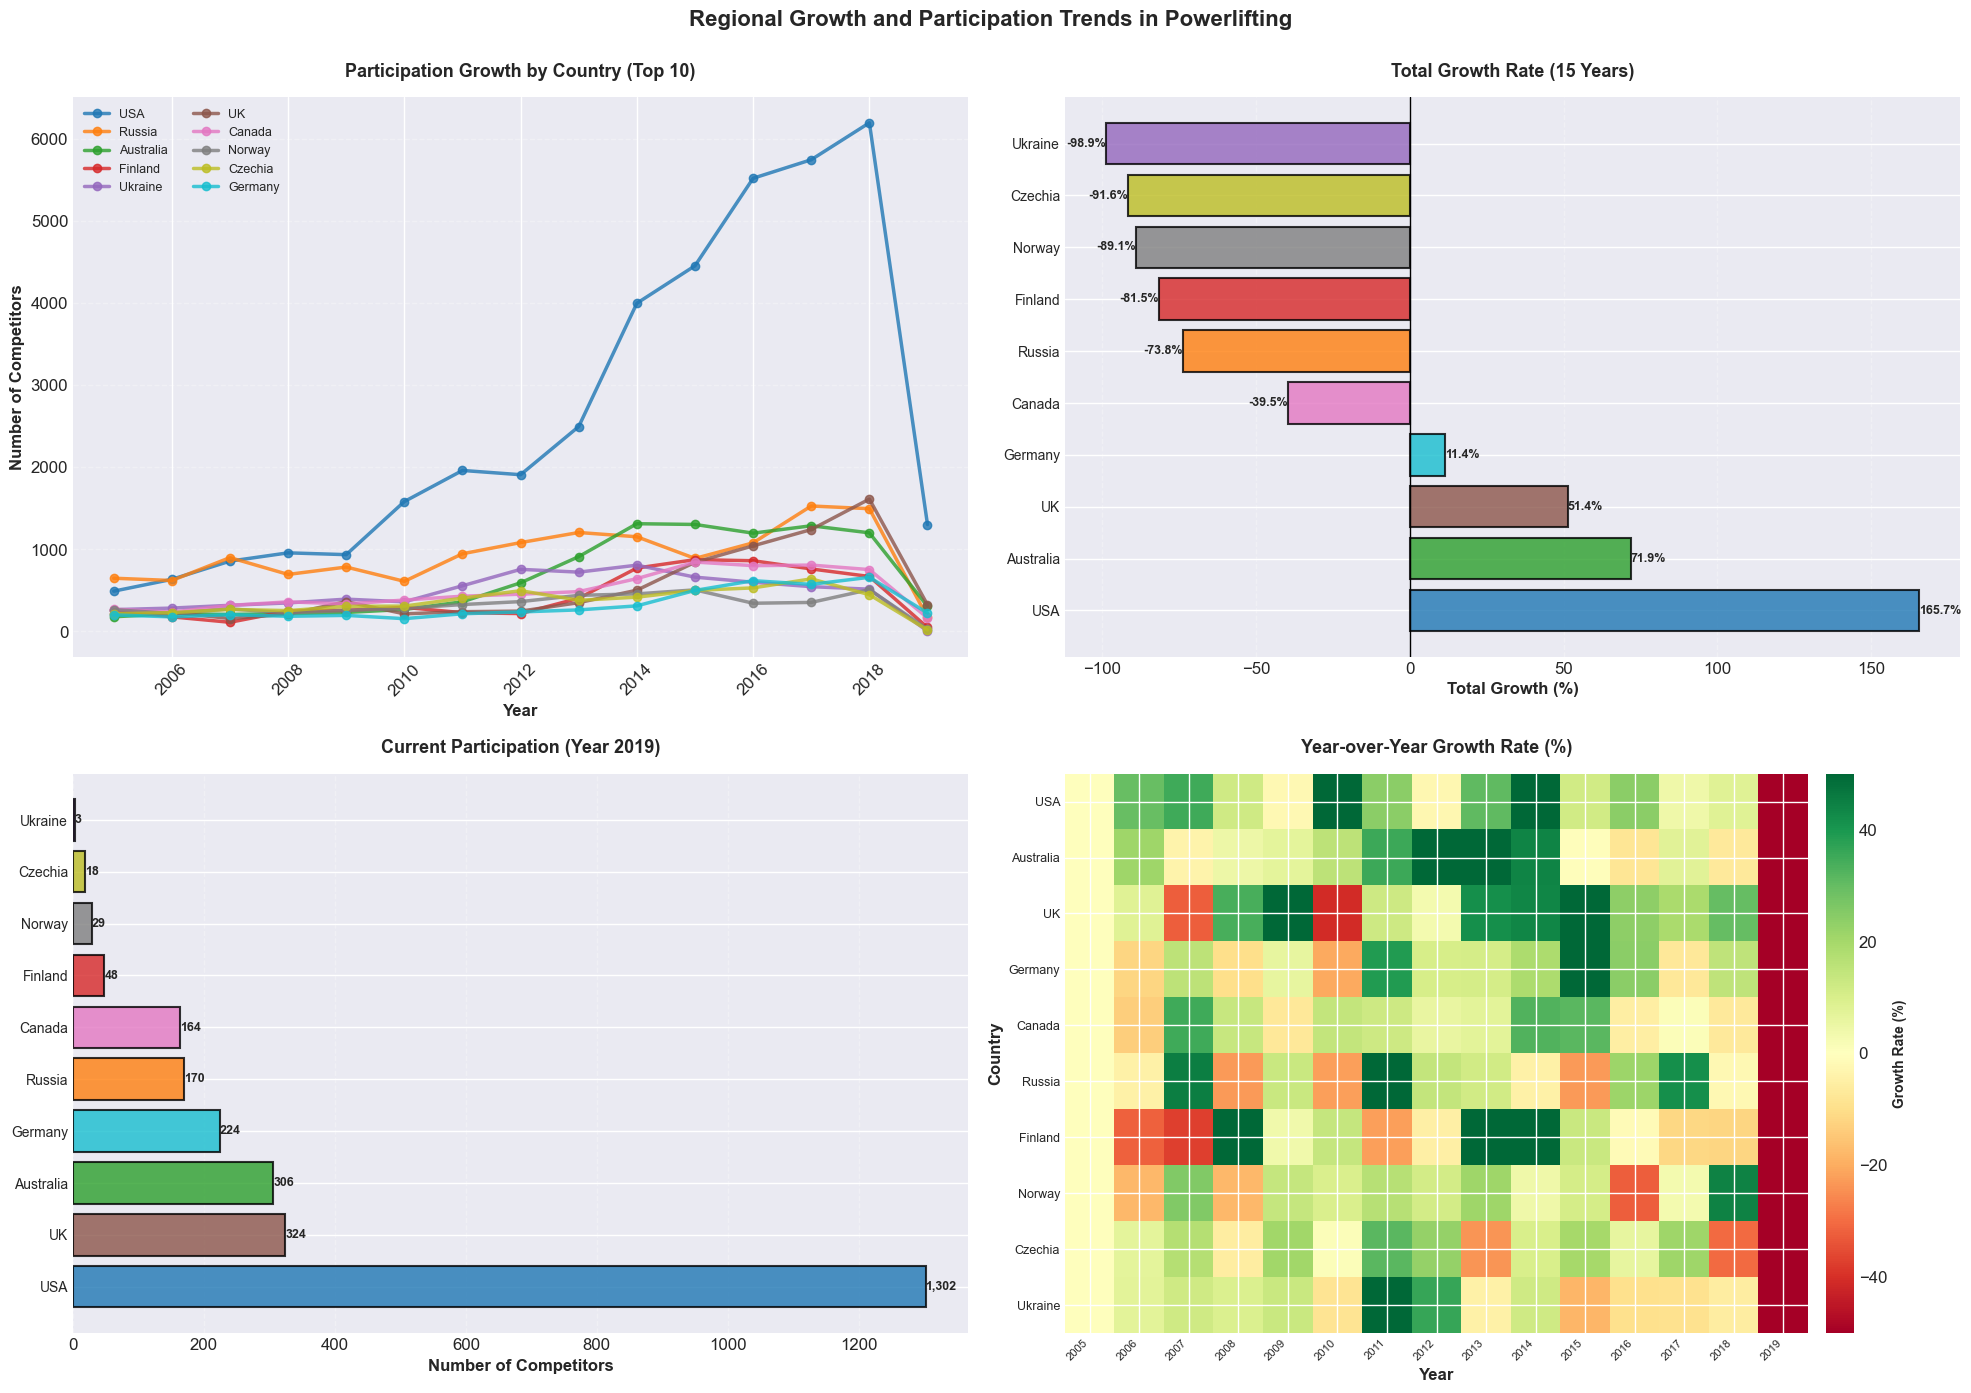


Regional Growth Summary:
Analysis period: 2005 - 2019

Top 10 Countries by Participation:
  1. USA: 1,302 competitors
  2. UK: 324 competitors
  3. Australia: 306 competitors
  4. Germany: 224 competitors
  5. Russia: 170 competitors
  6. Canada: 164 competitors
  7. Finland: 48 competitors
  8. Norway: 29 competitors
  9. Czechia: 18 competitors
  10. Ukraine: 3 competitors

Growth Leaders (Total % Growth):
  1. USA: 165.7% growth (490 → 1,302 competitors)
  2. Australia: 71.9% growth (178 → 306 competitors)
  3. UK: 51.4% growth (214 → 324 competitors)
  4. Germany: 11.4% growth (201 → 224 competitors)
  5. Canada: -39.5% growth (271 → 164 competitors)


In [82]:
# ============================================================================
# VISUALIZATION 6: Regional Growth and Participation Trends
# Inspired by: "Growth of Powerlifting by Age Group" and "Growth of Powerlifting by Region" articles
# ============================================================================

print("=" * 80)
print("VISUALIZATION 6: Regional Growth and Participation Trends")
print("=" * 80)

# Prepare data - focus on countries with sufficient data
df_viz6 = df_clean[df_clean['Country'].notna()].copy()
df_viz6 = df_viz6[df_viz6['Year'].notna()]

# Get top countries by total participation
country_counts = df_viz6['Country'].value_counts()
top_countries = country_counts.head(10).index.tolist()  # Top 10 countries

# Filter to top countries and last 15 years for better visualization
current_year = df_viz6['Year'].max()
start_year = current_year - 14  # Last 15 years
df_viz6_filtered = df_viz6[
    (df_viz6['Country'].isin(top_countries)) & 
    (df_viz6['Year'] >= start_year) & 
    (df_viz6['Year'] <= current_year)
].copy()

# Calculate participation by country and year
country_yearly = df_viz6_filtered.groupby(['Country', 'Year']).size().reset_index(name='Competitors')
country_yearly = country_yearly.sort_values(['Country', 'Year'])

# Calculate growth rates
country_growth = []
for country in top_countries:
    country_data = country_yearly[country_yearly['Country'] == country].sort_values('Year')
    if len(country_data) > 1:
        first_year = country_data.iloc[0]['Year']
        last_year = country_data.iloc[-1]['Year']
        first_count = country_data.iloc[0]['Competitors']
        last_count = country_data.iloc[-1]['Competitors']
        
        if first_count > 0:
            total_growth = ((last_count - first_count) / first_count) * 100
            avg_annual_growth = total_growth / (last_year - first_year) if (last_year - first_year) > 0 else 0
        else:
            total_growth = 0
            avg_annual_growth = 0
        
        country_growth.append({
            'Country': country,
            'FirstYear': first_year,
            'LastYear': last_year,
            'FirstCount': first_count,
            'LastCount': last_count,
            'TotalGrowth': total_growth,
            'AvgAnnualGrowth': avg_annual_growth
        })

growth_df = pd.DataFrame(country_growth).sort_values('TotalGrowth', ascending=False)

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# ===== TOP LEFT: Participation Over Time (Line Plot) =====
ax1 = axes[0, 0]

# Use distinct colors for each country
colors_country = plt.cm.tab10(np.linspace(0, 1, len(top_countries)))
country_color_map = {country: colors_country[i] for i, country in enumerate(top_countries)}

for country in top_countries:
    data = country_yearly[country_yearly['Country'] == country].sort_values('Year')
    if len(data) > 0:
        ax1.plot(data['Year'], data['Competitors'], 
                marker='o', markersize=6, linewidth=2.5,
                label=country, color=country_color_map[country], alpha=0.8)

ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Competitors', fontsize=12, fontweight='bold')
ax1.set_title('Participation Growth by Country (Top 10)', fontsize=13, fontweight='bold', pad=15)
ax1.legend(fontsize=9, ncol=2, framealpha=0.9, loc='upper left')
ax1.grid(alpha=0.3, linestyle='--', axis='y')
ax1.tick_params(axis='x', rotation=45)

# ===== TOP RIGHT: Total Growth Percentage (Bar Chart) =====
ax2 = axes[0, 1]

bars = ax2.barh(range(len(growth_df)), growth_df['TotalGrowth'], 
               color=[country_color_map.get(country, 'gray') for country in growth_df['Country']],
               alpha=0.8, edgecolor='black', linewidth=1.5)

ax2.set_yticks(range(len(growth_df)))
ax2.set_yticklabels(growth_df['Country'], fontsize=10)
ax2.set_xlabel('Total Growth (%)', fontsize=12, fontweight='bold')
ax2.set_title('Total Growth Rate (15 Years)', fontsize=13, fontweight='bold', pad=15)
ax2.grid(alpha=0.3, linestyle='--', axis='x')
ax2.axvline(x=0, color='black', linestyle='-', linewidth=1)

# Add value labels
for i, (idx, row) in enumerate(growth_df.iterrows()):
    ax2.text(row['TotalGrowth'], i, f"{row['TotalGrowth']:.1f}%", 
            ha='left' if row['TotalGrowth'] >= 0 else 'right', 
            va='center', fontsize=9, fontweight='bold')

# ===== BOTTOM LEFT: Current Participation (Bar Chart) =====
ax3 = axes[1, 0]

# Get latest year data for each country
latest_year_data = []
for country in top_countries:
    country_data = country_yearly[country_yearly['Country'] == country]
    if len(country_data) > 0:
        latest = country_data[country_data['Year'] == country_data['Year'].max()]
        if len(latest) > 0:
            latest_year_data.append({
                'Country': country,
                'Year': latest.iloc[0]['Year'],
                'Competitors': latest.iloc[0]['Competitors']
            })

latest_df = pd.DataFrame(latest_year_data).sort_values('Competitors', ascending=False)

bars = ax3.barh(range(len(latest_df)), latest_df['Competitors'],
               color=[country_color_map.get(country, 'gray') for country in latest_df['Country']],
               alpha=0.8, edgecolor='black', linewidth=1.5)

ax3.set_yticks(range(len(latest_df)))
ax3.set_yticklabels(latest_df['Country'], fontsize=10)
ax3.set_xlabel('Number of Competitors', fontsize=12, fontweight='bold')
ax3.set_title(f'Current Participation (Year {latest_df["Year"].iloc[0] if len(latest_df) > 0 else current_year})', 
             fontsize=13, fontweight='bold', pad=15)
ax3.grid(alpha=0.3, linestyle='--', axis='x')

# Add value labels
for i, (idx, row) in enumerate(latest_df.iterrows()):
    ax3.text(row['Competitors'], i, f"{int(row['Competitors']):,}", 
            ha='left', va='center', fontsize=9, fontweight='bold')

# ===== BOTTOM RIGHT: Growth Heatmap (Year-over-Year) =====
ax4 = axes[1, 1]

# Create pivot table for heatmap
pivot_data = country_yearly.pivot(index='Country', columns='Year', values='Competitors')
pivot_data = pivot_data.fillna(0)

# Calculate year-over-year growth percentage
growth_pivot = pivot_data.pct_change(axis=1) * 100
growth_pivot = growth_pivot.fillna(0)

# Sort by total growth
growth_pivot = growth_pivot.reindex(growth_df['Country'])

# Create heatmap
im = ax4.imshow(growth_pivot.values, cmap='RdYlGn', aspect='auto', vmin=-50, vmax=50)

ax4.set_yticks(range(len(growth_pivot)))
ax4.set_yticklabels(growth_pivot.index, fontsize=9)
ax4.set_xticks(range(len(growth_pivot.columns)))
ax4.set_xticklabels([int(year) for year in growth_pivot.columns], rotation=45, ha='right', fontsize=8)
ax4.set_xlabel('Year', fontsize=12, fontweight='bold')
ax4.set_ylabel('Country', fontsize=12, fontweight='bold')
ax4.set_title('Year-over-Year Growth Rate (%)', fontsize=13, fontweight='bold', pad=15)

# Add colorbar
cbar = plt.colorbar(im, ax=ax4, pad=0.02)
cbar.set_label('Growth Rate (%)', fontsize=10, fontweight='bold')

plt.suptitle('Regional Growth and Participation Trends in Powerlifting', 
            fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nRegional Growth Summary:")
print(f"Analysis period: {start_year} - {current_year}")
print(f"\nTop 10 Countries by Participation:")
for i, (idx, row) in enumerate(latest_df.iterrows(), 1):
    print(f"  {i}. {row['Country']}: {int(row['Competitors']):,} competitors")
    
print(f"\nGrowth Leaders (Total % Growth):")
for i, (idx, row) in enumerate(growth_df.head(5).iterrows(), 1):
    print(f"  {i}. {row['Country']}: {row['TotalGrowth']:.1f}% growth "
          f"({int(row['FirstCount']):,} → {int(row['LastCount']):,} competitors)")


In [83]:
# DIAGNOSTIC: Check actual weight class values for females
print("=" * 80)
print("DIAGNOSTIC: Female Weight Class Values in Dataset")
print("=" * 80)

# Get all female weight classes
female_data = df_clean[df_clean['Sex'] == 'F']
female_wc = female_data['WeightClassKg'].value_counts().head(20)

print("\nTop 20 Female Weight Classes in dataset:")
for i, (wc, count) in enumerate(female_wc.items(), 1):
    print(f"  {i}. '{wc}': {count:,} athletes")

print("\n" + "=" * 80)
print("Expected IPF Female Classes: 47, 52, 57, 63, 69, 76, 84, 84+")
print("=" * 80)

DIAGNOSTIC: Female Weight Class Values in Dataset

Top 20 Female Weight Classes in dataset:
  1. '75': 26,866 athletes
  2. '56': 21,581 athletes
  3. '67.5': 17,991 athletes
  4. '72': 17,653 athletes
  5. '63': 15,757 athletes
  6. '67.3': 15,321 athletes
  7. '52': 14,412 athletes
  8. '60': 13,061 athletes
  9. '90': 12,974 athletes
  10. '84': 12,143 athletes
  11. '60.1': 12,021 athletes
  12. '57': 10,672 athletes
  13. '51.9': 9,908 athletes
  14. '82.3': 9,281 athletes
  15. '84+': 8,857 athletes
  16. '82.5': 8,359 athletes
  17. '100': 6,968 athletes
  18. '47.8': 6,799 athletes
  19. '90+': 5,325 athletes
  20. '44.2': 5,174 athletes

Expected IPF Female Classes: 47, 52, 57, 63, 69, 76, 84, 84+


VISUALIZATION 1: Weight Class Distribution (Actual Dataset Classes)

Top 10 Female classes: ['75', '56', '67.5', '72', '63', '67.3', '52', '60', '90', '84']
Top 10 Male classes: ['90', '100', '82.5', '110', '75', '74.8', '93', '83', '67.1', '82.1']


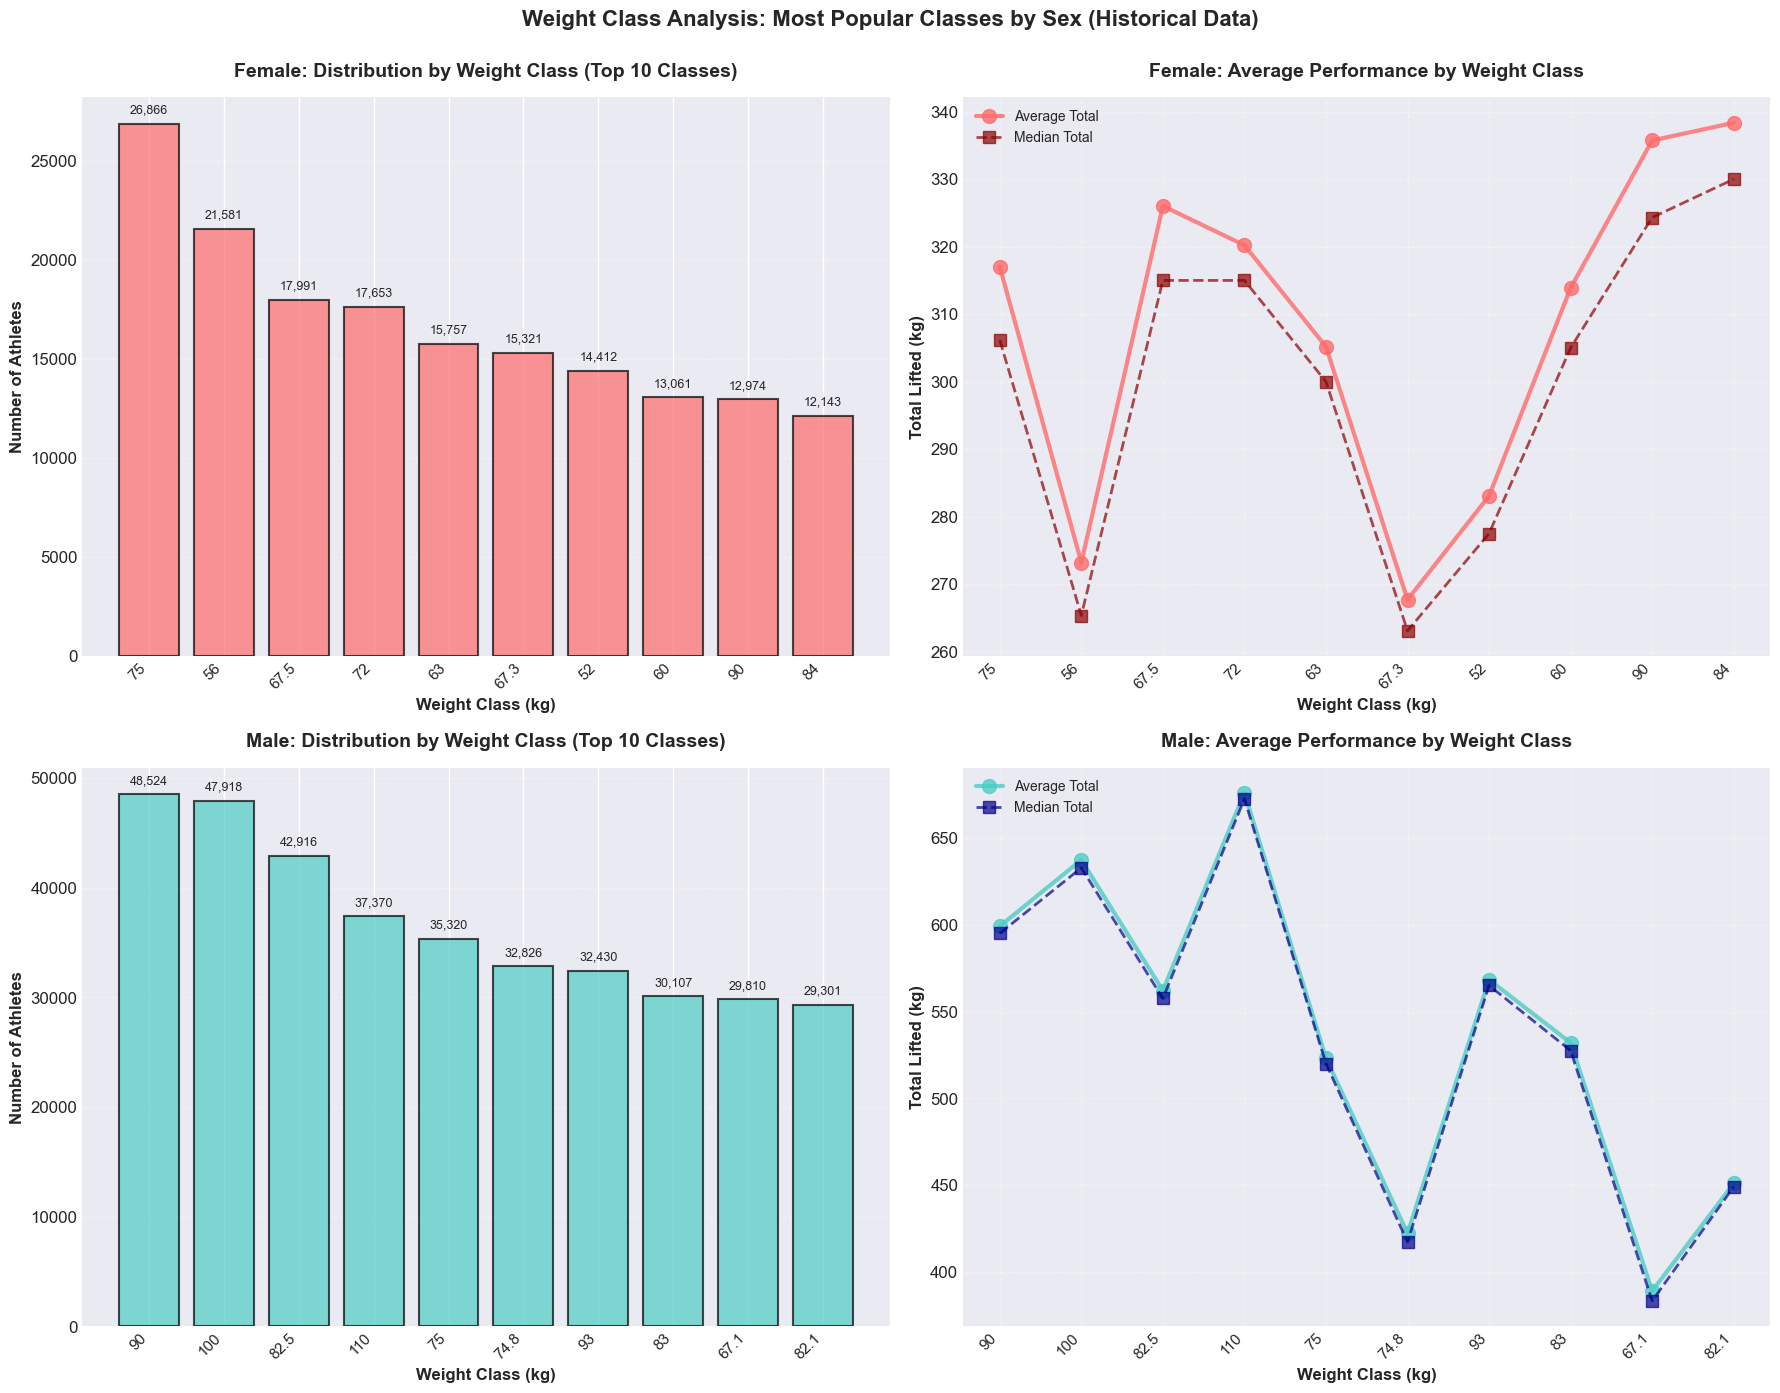


✓ Weight class visualization created using actual dataset classes!

Female - Top 5 classes:
  1. 75kg: 26,866 athletes (Avg: 317.0 kg)
  2. 56kg: 21,581 athletes (Avg: 273.2 kg)
  3. 67.5kg: 17,991 athletes (Avg: 326.0 kg)
  4. 72kg: 17,653 athletes (Avg: 320.2 kg)
  5. 63kg: 15,757 athletes (Avg: 305.2 kg)

Male - Top 5 classes:
  1. 90kg: 48,524 athletes (Avg: 599.1 kg)
  2. 100kg: 47,918 athletes (Avg: 637.3 kg)
  3. 82.5kg: 42,916 athletes (Avg: 562.1 kg)
  4. 110kg: 37,370 athletes (Avg: 675.9 kg)
  5. 75kg: 35,320 athletes (Avg: 523.1 kg)


In [84]:
# ============================================================================
# VISUALIZATION 1: Weight Class Distribution - USING ACTUAL DATASET CLASSES
# ============================================================================

print("=" * 80)
print("VISUALIZATION 1: Weight Class Distribution (Actual Dataset Classes)")
print("=" * 80)

# Get top weight classes for each sex from the actual dataset
female_top_classes = df_clean[df_clean['Sex'] == 'F']['WeightClassKg'].value_counts().head(10).index.tolist()
male_top_classes = df_clean[df_clean['Sex'] == 'M']['WeightClassKg'].value_counts().head(10).index.tolist()

print(f"\nTop 10 Female classes: {female_top_classes}")
print(f"Top 10 Male classes: {male_top_classes}")

# Filter data for these classes
df_female = df_clean[(df_clean['Sex'] == 'F') & (df_clean['WeightClassKg'].isin(female_top_classes))].copy()
df_male = df_clean[(df_clean['Sex'] == 'M') & (df_clean['WeightClassKg'].isin(male_top_classes))].copy()

# Calculate statistics
female_stats = df_female.groupby('WeightClassKg').agg({
    'TotalKg': ['count', 'mean', 'median']
}).reindex(female_top_classes)
female_stats.columns = ['Count', 'AvgTotal', 'MedianTotal']

male_stats = df_male.groupby('WeightClassKg').agg({
    'TotalKg': ['count', 'mean', 'median']
}).reindex(male_top_classes)
male_stats.columns = ['Count', 'AvgTotal', 'MedianTotal']

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
colors = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== ROW 1: FEMALE =====
# Left: Distribution
ax_f_dist = axes[0, 0]
x_f = np.arange(len(female_top_classes))

bars_f = ax_f_dist.bar(x_f, female_stats['Count'].fillna(0), 
                       color=colors['F'], edgecolor='black', linewidth=1.5, alpha=0.7)

ax_f_dist.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_f_dist.set_ylabel('Number of Athletes', fontsize=12, fontweight='bold')
ax_f_dist.set_title('Female: Distribution by Weight Class (Top 10 Classes)', 
                    fontsize=14, fontweight='bold', pad=15)
ax_f_dist.set_xticks(x_f)
ax_f_dist.set_xticklabels(female_top_classes, fontsize=11, rotation=45, ha='right')
ax_f_dist.grid(axis='y', alpha=0.3, linestyle='--')

# Add count labels
for i, count in enumerate(female_stats['Count'].fillna(0)):
    if count > 0:
        ax_f_dist.text(i, count + max(female_stats['Count'].fillna(0))*0.02, 
                      f'{int(count):,}', ha='center', fontsize=9)

# Right: Performance
ax_f_perf = axes[0, 1]

ax_f_perf.plot(x_f, female_stats['AvgTotal'].fillna(0), marker='o', linewidth=3, 
              markersize=10, color=colors['F'], label='Average Total', alpha=0.8)
ax_f_perf.plot(x_f, female_stats['MedianTotal'].fillna(0), marker='s', linewidth=2, 
              markersize=8, color='darkred', linestyle='--', label='Median Total', alpha=0.7)

ax_f_perf.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_f_perf.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax_f_perf.set_title('Female: Average Performance by Weight Class', 
                    fontsize=14, fontweight='bold', pad=15)
ax_f_perf.set_xticks(x_f)
ax_f_perf.set_xticklabels(female_top_classes, fontsize=11, rotation=45, ha='right')
ax_f_perf.legend(fontsize=10, loc='upper left')
ax_f_perf.grid(alpha=0.3, linestyle='--')

# ===== ROW 2: MALE =====
# Left: Distribution
ax_m_dist = axes[1, 0]
x_m = np.arange(len(male_top_classes))

bars_m = ax_m_dist.bar(x_m, male_stats['Count'].fillna(0), 
                       color=colors['M'], edgecolor='black', linewidth=1.5, alpha=0.7)

ax_m_dist.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_m_dist.set_ylabel('Number of Athletes', fontsize=12, fontweight='bold')
ax_m_dist.set_title('Male: Distribution by Weight Class (Top 10 Classes)', 
                    fontsize=14, fontweight='bold', pad=15)
ax_m_dist.set_xticks(x_m)
ax_m_dist.set_xticklabels(male_top_classes, fontsize=11, rotation=45, ha='right')
ax_m_dist.grid(axis='y', alpha=0.3, linestyle='--')

# Add count labels
for i, count in enumerate(male_stats['Count'].fillna(0)):
    if count > 0:
        ax_m_dist.text(i, count + max(male_stats['Count'].fillna(0))*0.02, 
                      f'{int(count):,}', ha='center', fontsize=9)

# Right: Performance
ax_m_perf = axes[1, 1]

ax_m_perf.plot(x_m, male_stats['AvgTotal'].fillna(0), marker='o', linewidth=3, 
              markersize=10, color=colors['M'], label='Average Total', alpha=0.8)
ax_m_perf.plot(x_m, male_stats['MedianTotal'].fillna(0), marker='s', linewidth=2, 
              markersize=8, color='darkblue', linestyle='--', label='Median Total', alpha=0.7)

ax_m_perf.set_xlabel('Weight Class (kg)', fontsize=12, fontweight='bold')
ax_m_perf.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax_m_perf.set_title('Male: Average Performance by Weight Class', 
                    fontsize=14, fontweight='bold', pad=15)
ax_m_perf.set_xticks(x_m)
ax_m_perf.set_xticklabels(male_top_classes, fontsize=11, rotation=45, ha='right')
ax_m_perf.legend(fontsize=10, loc='upper left')
ax_m_perf.grid(alpha=0.3, linestyle='--')

plt.suptitle('Weight Class Analysis: Most Popular Classes by Sex (Historical Data)', 
            fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("\n✓ Weight class visualization created using actual dataset classes!")
print(f"\nFemale - Top 5 classes:")
for i, (wc, count) in enumerate(female_stats['Count'].nlargest(5).items(), 1):
    if count > 0:
        print(f"  {i}. {wc}kg: {int(count):,} athletes (Avg: {female_stats.loc[wc, 'AvgTotal']:.1f} kg)")

print(f"\nMale - Top 5 classes:")
for i, (wc, count) in enumerate(male_stats['Count'].nlargest(5).items(), 1):
    if count > 0:
        print(f"  {i}. {wc}kg: {int(count):,} athletes (Avg: {male_stats.loc[wc, 'AvgTotal']:.1f} kg)")